# Romper una molécula, un qubit a la vez — H₄ con VQE

**Quantum Jam 2026 · equipo quantum-toffolis** (Octavio, Gonzalo, Santino, Joaquín)

Calculamos con **VQE** la curva de energía de la cadena lineal H₄ (STO-3G, 8 qubits con Jordan-Wigner) entre 0,6 y 3,0 Å y la comparamos con CCSD y FCI.

**Resumen de la estrategia**
1. Hamiltoniano por punto con PySCF → Jordan-Wigner (185 cadenas de Pauli).
2. Ansatz químico que conserva N_α y N_β, desde Hartree-Fock: **ADAPT-VQE** fermiónico, con una lista común de 15 excitaciones para toda la curva (194 CZ; 378 con qubits en línea usando un ruteo fSWAP propio).
3. Parámetros buscados sin ruido con gradiente analítico (permitido por la consigna).
4. **Energía reportada = medición con `SamplerV2` de `qiskit_aer`**: grupos QWC, rotación de base, shots repartidos en dos etapas (piloto + Neyman) y σ calculada desde las muestras.
5. R_e por ajuste cuártico en 7 puntos, elegido por su sesgo contra el mínimo FCI verdadero; incertidumbre por Monte Carlo. D_e = E(3,0 Å) − E(R_e).
6. Confiabilidad sin FCI, todo **medido con shots**: varianza de la energía (por grupos y por eco de Loschmidt), simetrías N_α, N_β y S², y convergencia con la profundidad.

Los extras (menos qubits, mitigación de errores, ruido de hardware con `FakeFez` y otra geometría) están en `H4_VQE_extras.ipynb`.

**Resultados** (ADAPT 15 operadores, 8M shots por punto, 194 CZ todos con todos):
- Precisión química en las 18 distancias (error máximo 1,15 mHa, a 0,7 Å). En la zona estirada (d ≥ 1,8 Å), error ≤ 0,56 mHa con σ ≈ 0,5 mHa, contra 9–31 mHa de CCSD: le ganamos en 7/7 puntos.
- R_e = 0,8873 ± 0,0018 Å (FCI: 0,8886 Å); D_e = 313,00 ± 0,66 mHa (FCI: 313,21 mHa).
- Varianza medida por eco ≤ 2·10⁻⁴ Ha² en 1,8, 2,4 y 3,0 Å (HF: 0,11–0,16 Ha²), y UCCSD ×2, con 3 veces más CZ, no baja la energía medida más allá de 1,6σ.
- Contra UCCSD ×2 (582 CZ, 1648 en línea) son 3 veces menos CZ con conectividad total y 4,4 veces menos en línea.


## 0 · Instalación y código

El notebook instala sus dependencias y escribe el paquete `h4vqe/` con `%%writefile`, así corre de punta a punta en un Colab nuevo.
Cada módulo tiene un dueño en el equipo; acá solo se copian.


In [1]:
# Instala dependencias si faltan (Colab arranca sin Qiskit ni PySCF).
import importlib.util, os, subprocess, sys
REQS = {"qiskit": "qiskit==2.6.2", "qiskit_aer": "qiskit-aer==0.18.4", "pyscf": "pyscf==2.15.0"}
missing = [pip for mod, pip in REQS.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
os.makedirs("h4vqe", exist_ok=True)
print("python", sys.version.split()[0], "- instalado:", missing or "nada (ya estaba)")

python 3.12.14 - instalado: nada (ya estaba)


In [2]:
%%writefile h4vqe/__init__.py
"""VQE para la curva de disociación de H4 lineal (Quantum Jam 2026)."""


Writing h4vqe/__init__.py


In [3]:
%%writefile h4vqe/config.py
"""Configuración compartida. Cambiar acá, no en los módulos.

Dueño: todos (avisar en el grupo antes de tocar).
"""

BASIS = "sto-3g"

# Distancias H-H (Å). La consigna pide >= 10 puntos entre 0,6 y 3,0 Å.
# Hay puntos densos cerca del mínimo (~0,9 Å) para ajustar R_e.
DISTANCES = [0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 1.0, 1.1, 1.2, 1.4, 1.6,
             1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0]

STRETCHED_FROM = 1.8          # zona donde hay que ganarle a CCSD
CHEM_ACC = 1.6e-3             # Ha

# Presupuesto de shots por punto de la curva (estimación final, no optimización).
SHOTS_PER_POINT = 8_000_000   # σ ≈ 0,5 mHa en la zona estirada (QWC con sorted insertion + Neyman)

# Compuertas nativas que fija la consigna para el extra con ruido: cz, sx, x y rz.
# (ruido.py no se distribuye; el modelo de ruido propio está en noise.py.)
BASIS_GATES = ["cz", "rz", "sx", "x"]

SEED = 1234

# Ansatz de la curva principal:
#   "adapt": ADAPT-VQE fermiónico, lista común de 15 operadores (adapt.ADAPT_FERMIONIC).
#            194 CZ todos con todos, 378 en línea con el ruteo fSWAP de routing.py.
#            Error sin ruido ≤ 0,38 mHa en toda la curva.
#   "uccsd": UCCSD con ANSATZ_REPS pasos de Trotter (582 CZ con 2 pasos; < 1 µHa sin ruido).
ANSATZ = "adapt"

# Pasos de Trotter de UCCSD. Con ANSATZ = "adapt", UCCSD ×2 queda como referencia más
# profunda (prueba de profundidad, comparación de ansätze, geometría y FakeFez).
# Con 1 paso el error máximo es ~4,5 mHa (a 2,0 Å): le gana a CCSD pero sin precisión química.
ANSATZ_REPS = 2


Writing h4vqe/config.py


In [4]:
%%writefile h4vqe/hamiltonian.py
"""Molécula H4 lineal -> hamiltoniano de qubits + referencias clásicas.

Dueño: Octavio.

Convención de qubits (Jordan-Wigner, little-endian de Qiskit):
    qubits 0..norb-1      -> espín-orbitales alfa (orbital 0 = el de menor energía)
    qubits norb..2norb-1  -> espín-orbitales beta
El estado HF ocupa los qubits 0,1 (alfa) y 4,5 (beta): bitstring '00110011'.
"""
from __future__ import annotations

import numpy as np
from pyscf import gto, scf, mcscf, ao2mo, cc
from qiskit.quantum_info import SparsePauliOp

from .config import BASIS


ZIGZAG_ANGLE = 120.0   # ángulo H-H-H de la cadena en zigzag (grados)


def h4_geometry(d: float, shape: str = "linear") -> str:
    """4 H con vecinos a d Å: cadena recta (la del desafío), cadena en zigzag o cuadrado de lado d."""
    if shape == "linear":
        xyz = [(0, 0, i * d) for i in range(4)]
    elif shape == "zigzag":
        a = np.radians(ZIGZAG_ANGLE / 2)
        xyz = [(i * d * np.sin(a), (i % 2) * d * np.cos(a), 0) for i in range(4)]
    elif shape == "square":
        xyz = [(0, 0, 0), (d, 0, 0), (d, d, 0), (0, d, 0)]
    else:
        raise ValueError(f"forma desconocida: {shape!r}")
    return "; ".join(f"H {x:.6f} {y:.6f} {z:.6f}" for x, y, z in xyz)


def molecule(d: float, basis: str = BASIS, shape: str = "linear") -> dict:
    """Integrales en base de orbitales HF + energías HF, FCI y CCSD."""
    mol = gto.M(atom=h4_geometry(d, shape), basis=basis, unit="Angstrom", verbose=0)
    hf = scf.RHF(mol)
    hf.conv_tol = 1e-10
    hf.kernel()
    norb = mol.nao_nr()
    nelec = mol.nelectron
    cas = mcscf.CASCI(hf, norb, nelec)
    h1, ecore = cas.get_h1cas()
    g = ao2mo.restore(1, cas.get_h2cas(), norb)
    e_fci = cas.kernel()[0]

    ccsd = cc.CCSD(hf)
    ccsd.conv_tol = 1e-9
    ccsd.max_cycle = 500
    ccsd.kernel()

    return {
        "d": d, "shape": shape, "mol": mol, "hf": hf, "norb": norb,
        "nelec": (nelec // 2, nelec // 2),
        "h": h1, "g": g, "constante": ecore,
        "e_hf": hf.e_tot, "e_fci": e_fci,
        "e_ccsd": ccsd.e_tot, "ccsd_converged": bool(ccsd.converged),
    }


def _annihilation_jw(p: int, n_qubits: int) -> SparsePauliOp:
    return SparsePauliOp.from_sparse_list(
        [("Z" * p + "X", list(range(p + 1)), 0.5),
         ("Z" * p + "Y", list(range(p + 1)), 0.5j)], n_qubits)


def annihilation_ops(n_qubits: int) -> list[SparsePauliOp]:
    return [_annihilation_jw(p, n_qubits) for p in range(n_qubits)]


def qubit_hamiltonian(m: dict) -> SparsePauliOp:
    """Ĥ = E_core + Σ h_pq a†_p a_q + ½ Σ g_pqrs a†_p a†_r a_s a_q  (Jordan-Wigner)."""
    norb = m["norb"]
    nq = 2 * norb
    h, g = m["h"], m["g"]
    a = annihilation_ops(nq)
    ad = [op.adjoint() for op in a]
    hop = [[[ad[s * norb + p].dot(a[s * norb + q]).simplify() for q in range(norb)]
            for p in range(norb)] for s in range(2)]
    terms = [SparsePauliOp("I" * nq, m["constante"])]
    for s in range(2):
        for p in range(norb):
            for q in range(norb):
                terms.append(h[p, q] * hop[s][p][q])
    for s in range(2):
        for t in range(2):
            for p in range(norb):
                for q in range(norb):
                    second = SparsePauliOp.sum([g[p, q, r, u] * hop[t][r][u]
                                                for r in range(norb) for u in range(norb)])
                    terms.append(0.5 * hop[s][p][q].dot(second))
                    if s == t:
                        for u in range(norb):
                            terms.append(-0.5 * g[p, q, q, u] * hop[s][p][u])
    return SparsePauliOp.sum(terms).simplify(atol=1e-10).chop(1e-10)


def number_operators(norb: int) -> dict[str, SparsePauliOp]:
    """N_alfa, N_beta y S^2 en qubits, para chequear simetrías del estado."""
    nq = 2 * norb
    a = annihilation_ops(nq)
    n = [a[p].adjoint().dot(a[p]).simplify() for p in range(nq)]
    na = SparsePauliOp.sum(n[:norb]).simplify()
    nb = SparsePauliOp.sum(n[norb:]).simplify()
    sz = 0.5 * (na - nb)
    sp = SparsePauliOp.sum([a[p].adjoint().dot(a[norb + p]) for p in range(norb)]).simplify()
    s2 = (sp.dot(sp.adjoint()) + sz.dot(sz) - sz).simplify(atol=1e-12)
    return {"N_alpha": na, "N_beta": nb, "S2": s2}


def exact_ground_energy(H: SparsePauliOp) -> float:
    """Diagonalización completa (256x256). Solo como chequeo contra FCI."""
    return float(np.linalg.eigvalsh(H.to_matrix())[0])


def sector_indices(norb: int, nelec: tuple[int, int]) -> np.ndarray:
    """Índices de la base computacional con N_alfa y N_beta fijos (bit q = ocupación del qubit q)."""
    i = np.arange(2 ** (2 * norb))
    bits = (i[:, None] >> np.arange(2 * norb)) & 1
    return i[(bits[:, :norb].sum(1) == nelec[0]) & (bits[:, norb:].sum(1) == nelec[1])]


def hf_index(norb: int, nelec: tuple[int, int]) -> int:
    """Índice del determinante HF: los n_alfa y n_beta orbitales más bajos ocupados."""
    return sum(1 << q for q in range(nelec[0])) + sum(1 << (norb + q) for q in range(nelec[1]))


def sector_ground_state(H: SparsePauliOp, norb: int, nelec: tuple[int, int]) -> tuple[float, np.ndarray]:
    """Estado fundamental de Ĥ solo en el sector (N_alfa, N_beta): 36x36 para H4 en vez de 256x256."""
    idx = sector_indices(norb, nelec)
    w, v = np.linalg.eigh(H.to_matrix(sparse=True)[idx][:, idx].toarray())
    psi = np.zeros(2 ** (2 * norb), dtype=complex)
    psi[idx] = v[:, 0]
    return float(w[0]), psi


def validation_table(distances) -> list[dict]:
    """Por distancia: chequeo de Ĥ contra PySCF (HF y FCI), peso de HF en FCI y error de CCSD."""
    rows = []
    s2_op = None
    for d in distances:
        m = molecule(d)
        H = qubit_hamiltonian(m)
        k = hf_index(m["norb"], m["nelec"])
        e_hf_q = H.to_matrix(sparse=True)[k, k].real
        e_sec, psi = sector_ground_state(H, m["norb"], m["nelec"])
        if s2_op is None:
            s2_op = number_operators(m["norb"])["S2"].to_matrix(sparse=True)
        rows.append({
            "d": d, "n_paulis": len(H),
            "err_hf": e_hf_q - m["e_hf"],             # <HF|Ĥ|HF> − E_HF(PySCF)
            "err_fci": e_sec - m["e_fci"],            # E_0(Ĥ, sector 2α2β) − E_FCI(PySCF)
            "s2": float(np.vdot(psi, s2_op @ psi).real),  # 0 = singulete
            "w_hf": abs(psi[k]) ** 2,                 # peso del determinante HF en el estado FCI
            "ccsd_minus_fci_mHa": 1e3 * (m["e_ccsd"] - m["e_fci"]),
            "ccsd_converged": m["ccsd_converged"],
        })
    return rows


Writing h4vqe/hamiltonian.py


In [5]:
%%writefile h4vqe/ansatz.py
"""Ansatz que conserva el número de partículas (UCCSD con Trotter, 1 paso por defecto).

Dueño: Gonzalo.

Cada excitación k es una compuerta exp(-i θ_k G_k) con G_k = i(T_k - T_k†).
Los términos de Pauli de un mismo G_k conmutan entre sí, así que el circuito
implementa EXACTAMENTE Π_k exp(-i θ_k G_k). Eso permite optimizar con un
simulador numpy rápido (`FastAnsatz`) y después medir el MISMO circuito con shots.

Interfaz que usan los otros módulos (no romperla):
    build_ansatz(m, ...) -> Ansatz   con .circuit (parametrizado), .fast, .excitations
    cz_count(circuit, coupling="all"|"line") -> int
"""
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import CouplingMap

from .config import BASIS_GATES, SEED
from .hamiltonian import annihilation_ops


def hf_occupation(m: dict) -> list[int]:
    norb = m["norb"]
    na, nb = m["nelec"]
    return list(range(na)) + [norb + i for i in range(nb)]


def uccsd_excitations(m: dict) -> list[tuple[tuple[int, ...], tuple[int, ...]]]:
    """Simples y dobles ocupado -> vacío que conservan S_z."""
    norb = m["norb"]
    na, nb = m["nelec"]
    occ = [list(range(na)), [norb + i for i in range(nb)]]
    vac = [list(range(na, norb)), [norb + i for i in range(nb, norb)]]
    ex = [((i,), (a,)) for s in range(2) for i in occ[s] for a in vac[s]]
    ex += [((i, j), (a, b)) for i in occ[0] for j in occ[1] for a in vac[0] for b in vac[1]]
    for s in range(2):
        for x, i in enumerate(occ[s]):
            for j in occ[s][x + 1:]:
                for y, a in enumerate(vac[s]):
                    for b in vac[s][y + 1:]:
                        ex.append(((i, j), (a, b)))
    return ex


def qubit_annihilation_ops(nq: int) -> list[SparsePauliOp]:
    """Q_p = (X_p + iY_p)/2, SIN cadena de Z (excitaciones de qubit, QEB)."""
    return [SparsePauliOp.from_sparse_list([("X", [p], 0.5), ("Y", [p], 0.5j)], nq)
            for p in range(nq)]


def excitation_generator(exc, nq: int, a=None, kind: str = "fermionic") -> SparsePauliOp:
    """G = i(T - T†), con T = a†_a a†_b a_j a_i.

    kind="fermionic": a_p de Jordan-Wigner (con cadenas Z).
    kind="qeb": excitación de qubit, Q_p sin cadenas Z (Yordanov et al., 2020/2021).
    Conserva N_alfa y N_beta igual, pero toca solo 2 o 4 qubits, así que
    cuesta menos CZ, sobre todo con qubits en línea.
    """
    if a is None:
        a = annihilation_ops(nq) if kind == "fermionic" else qubit_annihilation_ops(nq)
    src, dst = exc
    T = SparsePauliOp("I" * nq)
    for p in dst:
        T = T.dot(a[p].adjoint())
    for p in reversed(src):
        T = T.dot(a[p])
    return (1j * (T - T.adjoint())).simplify(atol=1e-12)


def _multiplexor_weights(n_ctrl: int) -> tuple[list[int], np.ndarray]:
    """RY multicontrolada (todos los controles en 1) con 2^n RY y 2^n CNOT (código Gray).

    Devuelve el orden de controles de las CNOT y los pesos w_k: RY(w_k φ) antes de la
    CNOT k. Con X^m antes de una RY(α), el ángulo efectivo es (−1)^m α, así que el
    ángulo total para los controles c es Σ_k (−1)^{m_k(c)} w_k φ. Se pide φ si c = 1…1
    y 0 si no (sistema lineal de ±1, invertible).
    """
    n = 2 ** n_ctrl
    order = [(k & -k).bit_length() - 1 if k < n else n_ctrl - 1 for k in range(1, n + 1)]
    M = np.zeros((n, n))
    for c in range(n):
        m = 0
        for k in range(n):
            M[c, k] = (-1) ** m
            m ^= (c >> order[k]) & 1
    f = np.zeros(n)
    f[n - 1] = 1.0
    return order, np.linalg.solve(M, f)


def excitation_circuit(exc, nq: int, theta, kind: str = "fermionic") -> QuantumCircuit:
    """Circuito compacto que implementa EXACTAMENTE exp(−iθG) para una excitación.

    Simple ((i,), (a,)):     CNOT(a→i), RY(2σθ) en a controlada por i, CNOT(a→i).
    Doble ((i, j), (a, b)):  escalera CNOT(i→j), CNOT(a→b), CNOT(a→i) que lleva el par
    |s1⟩ = |ij ocupados⟩, |s2⟩ = |ab ocupados⟩ a dos estados que difieren solo en a;
    después, RY(2σθ) en a controlada por i = 1, j = 0, b = 0 (8 CNOT); después, la
    escalera inversa. Total: 14 CNOT para la doble y 4 para la simple, actuando SOLO
    sobre los qubits de la excitación, lo que se rutea mucho mejor en línea que
    PauliEvolutionGate.
    Fermiónica: el signo σ de T|s1⟩ depende de la paridad de algunos qubits espectadores
    (cadenas Z de Jordan-Wigner). Se implementa con CNOT(q→a) antes y después de la
    rotación (X en el blanco invierte el ángulo de la RY).
    """
    src, dst = exc
    G = excitation_generator(exc, nq, kind=kind).to_matrix(sparse=True)
    s1 = sum(1 << q for q in src)
    s2 = sum(1 << q for q in dst)
    spect = [q for q in range(nq) if q not in src + dst]
    # -iθG = θ(T − T†): s1 -> cos θ s1 + σ sin θ s2, con σ = <s2|(-iG)|s1> = <s2|T|s1>
    sigma0 = np.real(-1j * G[s2, s1])
    parity = [q for q in spect
              if np.real(-1j * G[s2 | (1 << q), s1 | (1 << q)]) * sigma0 < 0]
    if len(src) == 1:
        (i,), (a,) = src, dst
        ladder = [(a, i)]
        ctrls, vals, target = [i], [1], a
    else:
        (i, j), (a, b) = src, dst
        ladder = [(i, j), (a, b), (a, i)]
        ctrls, vals, target = [i, j, b], [1, 0, 0], a
    order, w = _multiplexor_weights(len(ctrls))
    qc = QuantumCircuit(nq)
    for c, t in ladder:
        qc.cx(c, t)
    neg = [c for c, v in zip(ctrls, vals) if v == 0]
    for q in parity:
        qc.cx(q, target)
    if neg:
        qc.x(neg)
    for k, wk in enumerate(w):
        qc.ry(2.0 * sigma0 * wk * theta, target)
        qc.cx(ctrls[order[k]], target)
    if neg:
        qc.x(neg)
    for q in parity:
        qc.cx(q, target)
    for c, t in reversed(ladder):
        qc.cx(c, t)
    return qc


class FastAnsatz:
    """Simulador numpy exacto de Π_k exp(-i θ_k G_k)|HF> (solo para OPTIMIZAR)."""

    def __init__(self, generators: list[SparsePauliOp], hf_index: int, nq: int):
        self.G = [g.to_matrix(sparse=False) for g in generators]
        self.G2 = [G @ G for G in self.G]
        for G, G2 in zip(self.G, self.G2):  # exp cerrada requiere G^3 = G
            assert np.allclose(G2 @ G, G, atol=1e-10), "G^3 != G"
        self.psi0 = np.zeros(2 ** nq, dtype=complex)
        self.psi0[hf_index] = 1.0

    @classmethod
    def from_matrices(cls, G: list, G2: list, psi0: np.ndarray) -> "FastAnsatz":
        """Igual que el constructor, pero con matrices ya calculadas (lo usa ADAPT)."""
        obj = cls.__new__(cls)
        obj.G, obj.G2, obj.psi0 = list(G), list(G2), psi0
        return obj

    def state(self, theta) -> np.ndarray:
        psi = self.psi0
        for t, G, G2 in zip(theta, self.G, self.G2):
            # exp(-i t G) = I + (cos t - 1) G^2 - i sin t G
            psi = psi + (np.cos(t) - 1.0) * (G2 @ psi) - 1j * np.sin(t) * (G @ psi)
        return psi

    def energy_and_grad(self, theta, Hm: np.ndarray):
        """Energía y gradiente analítico (barrido hacia atrás)."""
        n = len(theta)
        states = [self.psi0]
        for t, G, G2 in zip(theta, self.G, self.G2):
            p = states[-1]
            states.append(p + (np.cos(t) - 1.0) * (G2 @ p) - 1j * np.sin(t) * (G @ p))
        psi = states[-1]
        lam = Hm @ psi
        e = float(np.real(np.vdot(psi, lam)))
        grad = np.zeros(n)
        for k in reversed(range(n)):
            # dE/dθ_k = 2 Re <λ| (-i G_k) |ψ_k>, con ψ_k el estado después de la compuerta k
            grad[k] = 2.0 * np.real(np.vdot(lam, -1j * (self.G[k] @ states[k + 1])))
            t, G, G2 = theta[k], self.G[k], self.G2[k]
            # λ <- U_k† λ
            lam = lam + (np.cos(t) - 1.0) * (G2 @ lam) + 1j * np.sin(t) * (G @ lam)
        return e, grad


@dataclass
class Ansatz:
    circuit: QuantumCircuit          # parametrizado, en compuertas nativas (sin acoplamiento)
    excitations: list
    fast: FastAnsatz
    params: ParameterVector
    meta: dict = field(default_factory=dict)

    @property
    def num_parameters(self) -> int:
        return len(self.params)


def build_ansatz(m: dict, excitations=None, reps: int = 1, kind: str = "fermionic") -> Ansatz:
    """UCCSD (o la lista de excitaciones que se pase, p. ej. la de ADAPT).

    kind="fermionic" (default) o "qeb" (excitaciones de qubit, ver excitation_generator).
    """
    norb = m["norb"]
    nq = 2 * norb
    excitations = list(excitations or uccsd_excitations(m)) * reps
    a = annihilation_ops(nq) if kind == "fermionic" else qubit_annihilation_ops(nq)
    gens = [excitation_generator(e, nq, a, kind) for e in excitations]
    theta = ParameterVector("θ", len(gens))
    qc = QuantumCircuit(nq)
    occ = hf_occupation(m)
    for q in occ:
        qc.x(q)
    for t, G in zip(theta, gens):
        qc.append(PauliEvolutionGate(G, time=t), range(nq))
    native = transpile(qc, basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=SEED)
    hf_index = sum(1 << q for q in occ)
    return Ansatz(native, excitations, FastAnsatz(gens, hf_index, nq), theta,
                  {"reps": reps, "n_qubits": nq, "kind": kind})


def cz_count(circuit: QuantumCircuit, coupling: str = "all", seed: int = SEED) -> int:
    """CZ después de transpilar. coupling='line' = qubits en línea (modelo de ruido)."""
    kw = {}
    if coupling == "line":
        kw["coupling_map"] = CouplingMap.from_line(circuit.num_qubits)
    t = transpile(circuit, basis_gates=BASIS_GATES, optimization_level=3,
                  seed_transpiler=seed, **kw)
    return int(t.count_ops().get("cz", 0))


Writing h4vqe/ansatz.py


In [6]:
%%writefile h4vqe/optimize.py
"""Búsqueda de parámetros SIN ruido (permitido por la consigna).

Dueño: Gonzalo.

Los θ* se buscan con el simulador numpy exacto del ansatz. La energía que se
REPORTA no sale de acá: sale de medir el circuito con shots (estimator.py).
"""
from __future__ import annotations

import numpy as np
from scipy.optimize import minimize

from .ansatz import Ansatz


def optimize_params(ans: Ansatz, H, x0=None, tol: float = 1e-10, maxiter: int = 2000,
                    n_restarts: int = 0, seed: int = 0) -> dict:
    """L-BFGS-B con gradiente analítico. Devuelve dict con x, energy, nfev.

    Siempre prueba también θ = 0 (|HF⟩), además del x0 dado (warm start de la distancia
    anterior), y se queda con la energía más baja (es variacional, así que el mínimo es el
    mejor). Con la lista ADAPT de 15 operadores, el warm start solo cae en mínimos malos
    a 2,6-3,0 Å (hasta 2 mHa), y desde θ = 0 da 0,05-0,15 mHa.
    """
    Hm = H.to_matrix(sparse=True)
    fun = lambda x: ans.fast.energy_and_grad(x, Hm)
    zero = np.zeros(ans.num_parameters)
    bases = [zero] if x0 is None else [np.asarray(x0, float), zero]
    rng = np.random.default_rng(seed)
    starts = list(bases)
    starts += [b + rng.normal(0, 0.1, ans.num_parameters) for b in bases for _ in range(n_restarts)]
    best = None
    for s in starts:
        r = minimize(fun, s, jac=True, method="L-BFGS-B",
                     options={"maxiter": maxiter, "ftol": tol, "gtol": 1e-8})
        if best is None or r.fun < best.fun:
            best = r
    return {"x": best.x, "energy": float(best.fun), "nfev": int(best.nfev),
            "success": bool(best.success)}


def exact_state(ans: Ansatz, x) -> np.ndarray:
    """Solo para diagnóstico (fidelidad, varianza). NUNCA para la energía reportada."""
    return ans.fast.state(x)


Writing h4vqe/optimize.py


In [7]:
%%writefile h4vqe/estimator.py
"""Energía MEDIDA con SamplerV2 de qiskit_aer, con barra de error ±σ.

Dueño: Santino.

Método:
  1. Se agrupan los términos de Pauli que conmutan qubit a qubit (QWC).
  2. Cada grupo se mide en su base (H para X, S†H para Y) con N_g shots.
  3. Cada shot da UNA muestra del observable del grupo O_g = Σ c_k P_k,
     así que E_g = media muestral y σ_g² = var muestral / N_g
     (las covarianzas dentro del grupo quedan incluidas).
  4. E = constante + Σ_g E_g ;  σ² = Σ_g σ_g²  (grupos independientes).

Interfaz: measure_energy(circuit_bound, H, total_shots, ...) -> dict

Asignación de shots en dos etapas (piloto + Neyman), ver measure_energy.

Implementación: para cada grupo se precalcula una tabla con el valor de O_g para
cada bitstring posible (2^n entradas). Los conteos se hacen con np.bincount
sobre el arreglo de bits del SamplerV2 (mucho más rápido que get_counts con
millones de shots). Los circuitos de medición se transpilan una sola vez
(`prepare_measurement`) y se pueden reusar entre llamadas.
"""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Pauli, SparsePauliOp, StabilizerState
from qiskit_aer.primitives import SamplerV2 as AerSampler

from .config import BASIS_GATES, SEED


def split_constant(H: SparsePauliOp) -> tuple[float, SparsePauliOp]:
    ident = "I" * H.num_qubits
    const = sum(c for p, c in H.to_list() if p == ident)
    rest = SparsePauliOp.from_list([(p, c) for p, c in H.to_list() if p != ident])
    return float(np.real(const)), rest


def measurement_groups(H: SparsePauliOp, method: str = "sorted",
                       grouping: str = "qwc") -> list[SparsePauliOp]:
    """Grupos de términos que se miden juntos.
    grouping="qwc": conmutan qubit a qubit (se miden con H / S†H por qubit).
    grouping="gc":  conmutan en general (se miden con un Clifford, ver diagonalize_group).
    method="sorted": sorted insertion (Crawford et al., Quantum 5, 385 (2021)): se recorren
        los términos por |c| decreciente y cada uno va al primer grupo compatible. Pone los
        términos grandes juntos y sus covarianzas se compensan: para H4 baja la σ²·N
        de Neyman ~1,9× (QWC) contra el coloreo (scripts/shots_study.py).
    method="coloring": group_commuting de qiskit (lo que se usaba antes)."""
    _, rest = split_constant(H)
    if method == "coloring":
        return rest.group_commuting(qubit_wise=(grouping == "qwc"))
    labels = [p.to_label() for p in rest.paulis]
    groups: list[tuple[list[str], list[int]]] = []  # (base común por qubit, índices)
    for k in np.argsort(-np.abs(rest.coeffs), kind="stable"):
        lab = labels[k]
        for basis, idx in groups:
            if grouping == "qwc":
                ok = all(a == "I" or b == "I" or a == b for a, b in zip(lab, basis))
            else:
                ok = all(rest.paulis[k].commutes(rest.paulis[j]) for j in idx)
            if ok:
                for q, a in enumerate(lab):
                    if a != "I":
                        basis[q] = a
                idx.append(k)
                break
        else:
            groups.append((list(lab), [k]))
    return [rest[idx] for _, idx in groups]


def _independent_generators(paulis) -> list:
    """Subconjunto independiente (en GF(2), vectores simplécticos [x|z]) que genera el grupo."""
    rows, gens = [], []
    for p in paulis:
        v = np.concatenate([p.x, p.z]).astype(np.uint8)
        for r, piv in rows:  # reducir contra los ya elegidos
            if v[piv]:
                v ^= r
        if v.any():
            piv = int(np.flatnonzero(v)[0])
            rows = [(r ^ v if r[piv] else r, pv) for r, pv in rows]
            rows.append((v, piv))
            gens.append(p)
    return gens


def diagonalize_group(group: SparsePauliOp) -> tuple[QuantumCircuit, SparsePauliOp]:
    """Clifford U tal que U P U† es un string de Z (con signo) para todo P del grupo.
    Se completa un conjunto independiente de generadores a un estado estabilizador
    C|0>; entonces C† P C = ±Z... y medir O_g en |ψ> = medir Σ c ±Z en C†|ψ>.
    Devuelve (circuito C†, O_g reescrito en Z con los signos en los coeficientes)."""
    gens = _independent_generators(group.paulis)
    C = StabilizerState.from_stabilizer_list([g.to_label() for g in gens],
                                             allow_underconstrained=True).clifford
    labels, coeffs = [], []
    for p, c in zip(group.paulis, group.coeffs):
        q = p.evolve(C, frame="h")  # C† P C
        assert not q.x.any() and q.phase in (0, 2), (p, q)
        labels.append(Pauli((q.z, np.zeros_like(q.x))).to_label())
        coeffs.append(c * (-1 if q.phase == 2 else 1))
    return C.adjoint().to_circuit(), SparsePauliOp(labels, coeffs)


def group_basis(group: SparsePauliOp) -> str:
    """Base común del grupo: por qubit X, Y, Z o I (string little-endian como Pauli)."""
    nq = group.num_qubits
    basis = ["I"] * nq
    for p in group.paulis:
        lab = p.to_label()  # lab[-1-q] es el qubit q
        for q in range(nq):
            ch = lab[-1 - q]
            if ch != "I":
                basis[q] = ch
    return "".join(reversed(basis))


def rotate_and_measure(circ: QuantumCircuit, basis: str) -> QuantumCircuit:
    qc = circ.copy()
    nq = qc.num_qubits
    for q in range(nq):
        ch = basis[-1 - q]
        if ch == "X":
            qc.h(q)
        elif ch == "Y":
            qc.sdg(q)
            qc.h(q)
    qc.measure_all()
    return qc


def value_table(group: SparsePauliOp) -> np.ndarray:
    """table[x] = valor de O_g = Σ c_k P_k cuando se mide el bitstring x (bit q = qubit q),
    ya rotado a la base del grupo (cada P_k actúa como Z en su soporte)."""
    nq = group.num_qubits
    xs = np.arange(2 ** nq, dtype=np.uint64)
    table = np.zeros(2 ** nq)
    for p, c in zip(group.paulis, np.real(group.coeffs)):
        mask = np.uint64(int(np.dot(p.z | p.x, 1 << np.arange(nq, dtype=np.int64))))
        parity = np.bitwise_count(xs & mask) & 1
        table += c * (1 - 2 * parity.astype(float))
    return table


def group_outcome_values(group: SparsePauliOp) -> np.ndarray:
    """Alias de value_table (nombre que usa h4vqe/noise.py)."""
    return value_table(group)


@dataclass
class MeasurementPlan:
    """Lo que no depende de los shots: grupos, circuitos transpilados y tablas de valores."""
    const: float
    groups: list
    circuits: list
    tables: list
    num_qubits: int

    @property
    def n_groups(self) -> int:
        return len(self.groups)


def prepare_measurement(circuit: QuantumCircuit, H: SparsePauliOp,
                        grouping: str = "qwc") -> MeasurementPlan:
    """grouping="qwc": rotaciones de 1 qubit (sin CZ extra).
    grouping="gc": un Clifford por grupo (menos shots, pero agrega CZ al circuito medido)."""
    const, _ = split_constant(H)
    groups = measurement_groups(H, grouping=grouping)
    if grouping == "qwc":
        circs = [rotate_and_measure(circuit, group_basis(g)) for g in groups]
        tables = [value_table(g) for g in groups]
    else:
        circs, tables = [], []
        for g in groups:
            diag, gz = diagonalize_group(g)
            qc = circuit.compose(diag)
            qc.measure_all()
            circs.append(qc)
            tables.append(value_table(gz))
    circs = transpile(circs, basis_gates=BASIS_GATES + ["measure"], optimization_level=1,
                      seed_transpiler=SEED)
    return MeasurementPlan(const, groups, circs, tables, circuit.num_qubits)


def allocate_shots(groups, total_shots: int, weights=None) -> list[int]:
    """Por defecto: N_g ∝ Σ|c_k| (proxy de la desviación del grupo).
    Con weights = σ_g estimadas -> asignación de Neyman (N_g ∝ σ_g)."""
    if weights is None:
        weights = np.array([np.sum(np.abs(g.coeffs)) for g in groups])
    w = np.asarray(weights, float)
    w = w / w.sum()
    shots = np.maximum(100, np.floor(w * total_shots)).astype(int)
    return shots.tolist()


def _bitarray_to_int(bitarray) -> np.ndarray:
    """BitArray del SamplerV2 -> entero por shot (bit q = qubit q)."""
    arr = bitarray.array  # (shots, nbytes) uint8, big-endian
    x = np.zeros(arr.shape[0], dtype=np.int64)
    for i in range(arr.shape[1]):
        x = (x << 8) | arr[:, i]
    return x


def _outcome_hist(bitarray, nq: int) -> np.ndarray:
    """Histograma de resultados (2^nq entradas) de un BitArray del SamplerV2. Lo usa noise.py."""
    return np.bincount(_bitarray_to_int(bitarray), minlength=2 ** nq)


def _sample_counts(plan: MeasurementPlan, shots, seed) -> np.ndarray:
    """Corre un circuito por grupo; devuelve conteos por bitstring, shape (n_groups, 2^n)."""
    # Una semilla INDEPENDIENTE por grupo. Con una sola corrida y seed fija, Aer usa
    # semillas consecutivas por circuito y vimos errores correlacionados entre grupos
    # (σ subestimada, desvíos de 4σ). SeedSequence da flujos independientes.
    ss = seed if isinstance(seed, np.random.SeedSequence) else np.random.SeedSequence(seed)
    seeds = ss.generate_state(plan.n_groups)
    counts = np.zeros((plan.n_groups, 2 ** plan.num_qubits))
    for i, (c, n, sd) in enumerate(zip(plan.circuits, shots, seeds)):
        r = AerSampler(seed=int(sd)).run([(c, None, int(n))]).result()[0]
        counts[i] = _outcome_hist(r.data.meas, plan.num_qubits)
    return counts


def _combine(const, hists, values):
    """E = const + Σ_g media_g ; σ² = Σ_g var_g / N_g, a partir de los histogramas
    hists (G, 2^n) y las tablas de valores values (G, 2^n). Firma usada también por noise.py."""
    hists, values = np.asarray(hists, float), np.asarray(values, float)
    n = hists.sum(axis=1)
    mean = np.einsum("gx,gx->g", hists, values) / n
    svar = np.einsum("gx,gx->g", hists, (values - mean[:, None]) ** 2) / (n - 1)
    return const + mean.sum(), np.sqrt(np.sum(svar / n)), np.sqrt(svar)


def bootstrap_sigma(plan: MeasurementPlan, stage_counts: list[np.ndarray], n_boot: int = 200,
                    seed: int = 0) -> float:
    """σ por bootstrap: se re-muestrean los shots de cada grupo y de cada etapa
    (multinomial con las frecuencias observadas, mismo N) y se recalcula E.
    Chequeo cruzado de la σ analítica, sin suponer normalidad."""
    rng = np.random.default_rng(seed)
    T = np.array(plan.tables)
    n_tot = sum(c.sum(1) for c in stage_counts)                    # (n_groups,)
    E_b = np.zeros(n_boot)
    for g in range(plan.n_groups):
        s = np.zeros(n_boot)
        for counts in stage_counts:
            n = int(counts[g].sum())
            if n == 0:
                continue
            p = counts[g] / n
            s += rng.multinomial(n, p / p.sum(), size=n_boot) @ T[g]
        E_b += s / n_tot[g]
    return float(np.std(E_b, ddof=1))


def measure_energy(circuit: QuantumCircuit, H: SparsePauliOp, total_shots: int,
                   seed: int = SEED, pilot_fraction: float = 0.1,
                   return_details: bool = False, plan: MeasurementPlan | None = None,
                   weights=None, n_boot: int = 0, grouping: str = "qwc") -> dict:
    """circuit: ansatz con parámetros YA asignados, sin mediciones.

    Dos etapas:
      1. piloto (pilot_fraction del presupuesto) con N_g ∝ Σ|c_k|  -> estima σ_g;
      2. resto con asignación de Neyman N_g ∝ σ_g (minimiza σ total para N fijo).
    Las muestras de ambas etapas se juntan (misma distribución).
    pilot_fraction=1 -> una sola etapa con N_g ∝ Σ|c_k|.
    weights=array -> una sola etapa con N_g ∝ weights (p. ej. σ_g teóricas).

    plan: resultado de prepare_measurement(circuit, H) para no re-transpilar
          (si se pasa, circuit y H no se usan).
    n_boot > 0: agrega "sigma_boot" (σ por bootstrap con n_boot réplicas).
    grouping: "qwc" (default) o "gc" (conmutación general + Clifford), ver prepare_measurement.
    """
    plan = plan or prepare_measurement(circuit, H, grouping=grouping)
    seed_pilot, seed_rest, seed_boot = np.random.SeedSequence(seed).spawn(3)
    if weights is not None:
        pilot_fraction, w_pilot = 1.0, weights
    else:
        w_pilot = None
    T = np.array(plan.tables)
    stage_counts = [_sample_counts(plan, allocate_shots(plan.groups, int(total_shots * pilot_fraction),
                                                        weights=w_pilot), seed_pilot)]
    counts = stage_counts[0]
    rest = total_shots - int(counts.sum())
    if rest > 0 and pilot_fraction < 1:
        _, _, sg = _combine(plan.const, counts, T)
        stage_counts.append(_sample_counts(plan, allocate_shots(plan.groups, rest, weights=sg + 1e-12),
                                           seed_rest))
        counts = counts + stage_counts[1]
    E, sigma, sg = _combine(plan.const, counts, T)
    n = counts.sum(axis=1)
    out = {"energy": float(E), "sigma": float(sigma), "shots": int(n.sum()),
           "n_groups": plan.n_groups}
    if n_boot:
        out["sigma_boot"] = bootstrap_sigma(plan, stage_counts, n_boot,
                                            int(seed_boot.generate_state(1)[0]))
    if return_details:
        out["groups"] = [{"n_terms": len(g), "shots": int(ng), "mean": float(c @ t / ng), "std_sample": s}
                         for g, c, t, ng, s in zip(plan.groups, counts, T, n, sg)]
    return out


Writing h4vqe/estimator.py


In [8]:
%%writefile h4vqe/adapt.py
"""ADAPT-VQE: arma el ansatz agregando de a una excitación (la de gradiente máximo).

Dueño: Gonzalo.

Idea (Grimsley et al., Nat. Commun. 10, 3007, 2019):
    1. Arrancar de |HF> con el ansatz vacío.
    2. Para cada operador G_k del pool, el gradiente de agregar exp(-i θ G_k) al final
       (con θ = 0) es  g_k = <ψ| i[G_k, H] |ψ> = 2 Re <Hψ| -i G_k ψ>.
    3. Agregar el de |g_k| máximo y reoptimizar TODOS los parámetros (warm start).
    4. Repetir hasta que max|g_k| < grad_tol (criterio que NO usa FCI).
       Ojo: con 1e-4 se traba en mesetas: a 1,6, 2,8 y 3,0 Å se detiene con 0,6 a 2 mHa
       de error, y después el gradiente vuelve a crecer. Con 1e-5 llega a FCI en toda la curva.

Un mismo operador se puede elegir más de una vez.

La búsqueda es sin ruido con `FastAnsatz` (permitido por la consigna). La lista que
devuelve se pasa a `build_ansatz(m, excitations=lista)`, que arma el circuito
que después se mide con shots.

Funciones:
    adapt_vqe(m, H, ...)         -> lista propia para UNA geometría
    adapt_vqe_multi(ms, Hs, ...) -> UNA lista común para varias geometrías
"""
from __future__ import annotations

import numpy as np
from scipy.optimize import minimize

from .ansatz import (FastAnsatz, excitation_generator, hf_occupation, qubit_annihilation_ops,
                     uccsd_excitations)
from .hamiltonian import annihilation_ops


def fermionic_pool(m: dict) -> list:
    """Las 26 excitaciones simples y dobles ocupado -> vacío de UCCSD (conservan S_z)."""
    return uccsd_excitations(m)


class _Pool:
    """Matrices G_k y G_k² del pool y estado HF, calculadas una sola vez."""

    def __init__(self, m: dict, excitations: list, kind: str = "fermionic"):
        nq = 2 * m["norb"]
        a = annihilation_ops(nq) if kind == "fermionic" else qubit_annihilation_ops(nq)
        self.excitations = list(excitations)
        self.G = [excitation_generator(e, nq, a, kind).to_matrix(sparse=False)
                  for e in excitations]
        self.G2 = [G @ G for G in self.G]
        self.psi0 = np.zeros(2 ** nq, dtype=complex)
        self.psi0[sum(1 << q for q in hf_occupation(m))] = 1.0

    def fast(self, idx: list[int]) -> FastAnsatz:
        return FastAnsatz.from_matrices([self.G[i] for i in idx], [self.G2[i] for i in idx],
                                        self.psi0)

    def gradients(self, psi: np.ndarray, Hpsi: np.ndarray) -> np.ndarray:
        return np.array([2.0 * np.real(np.vdot(Hpsi, -1j * (G @ psi))) for G in self.G])


def _reoptimize(fast: FastAnsatz, Hm, x0: np.ndarray) -> tuple[np.ndarray, float]:
    r = minimize(lambda x: fast.energy_and_grad(x, Hm), x0, jac=True, method="L-BFGS-B",
                 options={"maxiter": 5000, "ftol": 1e-14, "gtol": 1e-9})
    return r.x, float(r.fun)


def adapt_vqe(m: dict, H, pool: list | None = None, grad_tol: float = 1e-5,
              max_ops: int = 40, e_ref: float | None = None, err_tol: float | None = None,
              kind: str = "fermionic", verbose: bool = False) -> dict:
    """ADAPT-VQE para una geometría.

    Criterio de parada principal: max|g_k| < grad_tol (no usa FCI).
    `e_ref`/`err_tol` (por ejemplo FCI y 0,5 mHa) son opcionales y solo para diagnóstico.
    """
    pool = _Pool(m, pool or fermionic_pool(m), kind)
    Hm = H.to_matrix(sparse=True)
    idx: list[int] = []
    x = np.zeros(0)
    psi = pool.psi0
    energy = float(np.real(np.vdot(psi, Hm @ psi)))
    history = [{"n_ops": 0, "energy": energy, "max_grad": None, "added": None}]
    reason = "max_ops"
    for _ in range(max_ops):
        g = pool.gradients(psi, Hm @ psi)
        k = int(np.argmax(np.abs(g)))
        history[-1]["max_grad"] = float(abs(g[k]))
        if abs(g[k]) < grad_tol:
            reason = "grad_tol"
            break
        if e_ref is not None and err_tol is not None and energy - e_ref < err_tol:
            reason = "err_tol"
            break
        idx.append(k)
        fast = pool.fast(idx)
        x, energy = _reoptimize(fast, Hm, np.append(x, 0.0))
        psi = fast.state(x)
        history.append({"n_ops": len(idx), "energy": energy, "max_grad": None,
                        "added": pool.excitations[k]})
        if verbose:
            err = f"  err={1e3 * (energy - e_ref):.4f} mHa" if e_ref is not None else ""
            print(f"  op {len(idx):2d}: {pool.excitations[k]}  |g|={abs(g[k]):.2e}  "
                  f"E={energy:.8f}{err}")
    return {"excitations": [pool.excitations[i] for i in idx], "x": x, "energy": energy,
            "history": history, "stop": reason}


def line_cost(order: list[int], exc) -> tuple[float, list[int]]:
    """Costo en CZ de agregar `exc` con qubits en línea (ruteo con fSWAP de routing.py).

    Devuelve (CZ aproximadas, nuevo orden de modos). Doble en línea ≈ 18 CZ, simple ≈ 2,
    cada fSWAP ≈ 2.
    """
    from qiskit import QuantumCircuit
    from .routing import _gather
    new = list(order)
    n_sw = _gather(QuantumCircuit(len(order)), new, list(exc[0]) + list(exc[1]))
    return (18.0 if len(exc[0]) == 2 else 2.0) + 2.0 * n_sw, new


def adapt_vqe_multi(ms: list[dict], Hs: list, pool: list | None = None,
                    grad_tol: float = 1e-5, max_ops: int = 40, kind: str = "fermionic",
                    init_order: list[int] | None = None, cost_power: float = 0.0,
                    verbose: bool = False) -> dict:
    """UNA lista de excitaciones común a varias geometrías.

    En cada paso se calcula el gradiente de cada operador en TODAS las geometrías y se
    agrega el de mayor max_d |g_k(d)|; después se reoptimiza cada geometría por separado
    (sus θ son distintos, pero el circuito y la cantidad de CZ son los mismos).
    Para cuando el gradiente máximo es < grad_tol en todas las geometrías.

    Co-ADAPT (Ramôa et al. 2026): con cost_power > 0 el puntaje es
    max_d|g_k| / costo_k^cost_power, donde costo_k son las CZ en línea de agregar el
    operador dado el orden actual de modos (seguido como en routing.routed_ansatz,
    arrancando en init_order). Así la lista sale barata de rutear EN ESE ORDEN.
    """
    pools = [_Pool(m, pool or fermionic_pool(m), kind) for m in ms]
    Hms = [H.to_matrix(sparse=True) for H in Hs]
    idx: list[int] = []
    xs = [np.zeros(0) for _ in ms]
    psis = [p.psi0 for p in pools]
    energies = [float(np.real(np.vdot(s, Hm @ s))) for s, Hm in zip(psis, Hms)]
    history = []
    reason = "max_ops"
    order = list(init_order or range(2 * ms[0]["norb"]))
    for _ in range(max_ops):
        G = np.array([p.gradients(s, Hm @ s) for p, s, Hm in zip(pools, psis, Hms)])
        gmax = np.max(np.abs(G), axis=0)
        if gmax.max() < grad_tol:
            reason = "grad_tol"
            break
        if cost_power > 0:
            costs = [line_cost(order, e) for e in pools[0].excitations]
            score = gmax / np.array([c for c, _ in costs]) ** cost_power
            score[gmax < grad_tol] = -1.0
        else:
            costs, score = None, gmax
        k = int(np.argmax(score))
        if costs is not None:
            order = costs[k][1]
        idx.append(k)
        for j, (p, Hm) in enumerate(zip(pools, Hms)):
            fast = p.fast(idx)
            xs[j], energies[j] = _reoptimize(fast, Hm, np.append(xs[j], 0.0))
            psis[j] = fast.state(xs[j])
        history.append({"n_ops": len(idx), "added": pools[0].excitations[k],
                        "max_grad": float(gmax[k]),
                        "line_cost": costs[k][0] if costs is not None else None,
                        "energies": list(energies)})
        if verbose:
            extra = f"  costo línea≈{costs[k][0]:.0f}" if costs is not None else ""
            print(f"  op {len(idx):2d}: {pools[0].excitations[k]}  max|g|={gmax[k]:.2e}{extra}")
    return {"excitations": [pools[0].excitations[i] for i in idx], "xs": xs,
            "energies": energies, "history": history, "stop": reason}


# --------------------------------------------------------------------------------------
# Listas ya calculadas (para no correr ADAPT en Colab). Se regeneran con:
#   adapt_vqe_multi([molecule(d) for d in DISTANCES], [...], kind=..., grad_tol=1e-5)
# y truncando a los primeros k operadores. Excitaciones: ((ocupados), (vacíos)),
# qubits 0-3 = alfa, 4-7 = beta (convención de hamiltonian.py).
# --------------------------------------------------------------------------------------

# Recomendado (15 ops). La lista común de ADAPT truncada en 13 operadores, más las dos
# simples que completan los PARES DE ESPÍN (β 4→6 junto a α 0→2, α 1→3 junto a β 5→7).
# Sin ruido, con optimize_params (warm start + θ = 0): error máx. 0,38 mHa en TODA la
# curva, S² ≤ 6,5e-3; 194 CZ todos con todos; 378 en línea con routing.routed_ansatz + LINE_ORDER
# (~530 con el transpiler común). Var(H) exacta máx. sobre la curva: 1,9e-4 Ha².
# Las simples agregadas AL FINAL, en cambio, caen en un mínimo malo (2,5 mHa, S² = 0,52).
ADAPT_FERMIONIC = [
    ((1, 5), (3, 7)), ((0, 5), (3, 6)), ((0, 4), (2, 6)), ((1, 4), (2, 7)),
    ((1, 5), (2, 6)), ((0, 5), (2, 7)), ((0, 4), (3, 7)), ((1, 4), (3, 6)),
    ((0, 1), (2, 3)), ((4, 5), (6, 7)),
    ((0,), (2,)), ((4,), (6,)), ((5,), (7,)), ((1,), (3,)),
    ((0, 5), (2, 7)),
]

# Lista original de ADAPT truncada en 13 operadores (sin completar los pares de espín).
# Error máx. 0,59 mHa (2,0 Å); S² ≤ 0,013; 185 CZ / 370 en línea.
# Corte elegido por la varianza ⟨H²⟩ − ⟨H⟩² calculada con el estado (cae de 3,2e-3 a
# 2,6e-4 Ha² en k = 13); el eco de Loschmidt de analysis.py la confirma MEDIDA con shots.
ADAPT_FERMIONIC_13 = [
    ((1, 5), (3, 7)), ((0, 5), (3, 6)), ((0, 4), (2, 6)), ((1, 4), (2, 7)),
    ((1, 5), (2, 6)), ((0, 5), (2, 7)), ((0, 4), (3, 7)), ((1, 4), (3, 6)),
    ((0, 1), (2, 3)), ((4, 5), (6, 7)), ((0,), (2,)), ((5,), (7,)), ((0, 5), (2, 7)),
]

# Extra. Pool QEB (excitaciones de qubit), primeros 15 operadores: 159 CZ / ~451 en línea.
# Con optimize_params (warm start + θ = 0): error máx. 0,81 mHa, S² ≤ 0,074. Solo con warm
# start caía en un mínimo malo a 2,0 Å (9,8 mHa, S² = 0,78).
# Usar con build_ansatz(m, excitations=ADAPT_QEB, kind="qeb").
ADAPT_QEB = [
    ((1, 5), (3, 7)), ((0, 5), (3, 6)), ((0, 4), (2, 6)), ((1, 4), (2, 7)),
    ((1, 5), (2, 6)), ((0, 5), (2, 7)), ((0, 4), (3, 7)), ((1, 4), (3, 6)),
    ((0, 1), (2, 3)), ((4, 5), (6, 7)), ((0,), (2,)), ((5,), (7,)), ((4,), (6,)),
    ((1,), (3,)), ((0, 5), (2, 7)),
]


Writing h4vqe/adapt.py


In [9]:
%%writefile h4vqe/routing.py
"""Ruteo manual para qubits EN LÍNEA con fSWAP y orden de modos seguido clásicamente.

Dueño: Gonzalo.

Idea (Co-ADAPT, Ramôa et al., arXiv:2601.20681, 2026; redes fSWAP, Kivlichan et al. 2018):
    - El transpiler con SWAP comunes multiplica las CZ ~2,8× en línea (194 → ~530).
    - Un fSWAP entre qubits vecinos intercambia dos MODOS fermiónicos (incluido el signo
      de Jordan-Wigner) y cuesta 2 CZ (es iSWAP salvo fases locales). Un SWAP cuesta 3.
    - Antes de cada excitación juntamos sus modos en qubits contiguos con fSWAP y NO
      deshacemos la permutación: llevamos clásicamente el orden `order[q] = modo en el
      qubit q`. Con los modos contiguos, la excitación fermiónica no necesita CNOT de
      paridad (no hay espectadores en el medio).
    - Al final, el estado está escrito en Jordan-Wigner con el orden final de modos, así
      que la energía se mide con `hamiltonian_in_order(m, order_final)`.

Los θ son los MISMOS que los del ansatz sin rutear (las fSWAP solo reetiquetan modos),
así que se optimiza con FastAnsatz como siempre y se mide este circuito.
"""
from __future__ import annotations

import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp

from .ansatz import _multiplexor_weights, excitation_circuit, excitation_generator, hf_occupation
from .hamiltonian import annihilation_ops


def fswap(qc: QuantumCircuit, q: int) -> None:
    """fSWAP entre q y q+1: SWAP seguido de CZ (2 CZ después de transpilar)."""
    qc.swap(q, q + 1)
    qc.cz(q, q + 1)


def hamiltonian_in_order(m: dict, order: list[int]) -> SparsePauliOp:
    """Ĥ en Jordan-Wigner con el espín-orbital order[q] en el qubit q.

    Misma fórmula que hamiltonian.qubit_hamiltonian (espín-orbital = s*norb + p), pero
    con los modos reordenados. Con order = range(2*norb) da el mismo Ĥ.
    """
    norb = m["norb"]
    nq = 2 * norb
    pos = np.argsort(order)                     # pos[modo] = qubit
    a_q = annihilation_ops(nq)
    a = [a_q[pos[so]] for so in range(nq)]
    ad = [op.adjoint() for op in a]
    h, g = m["h"], m["g"]
    hop = [[[ad[s * norb + p].dot(a[s * norb + q]).simplify() for q in range(norb)]
            for p in range(norb)] for s in range(2)]
    terms = [SparsePauliOp("I" * nq, m["constante"])]
    for s in range(2):
        for p in range(norb):
            for q in range(norb):
                terms.append(h[p, q] * hop[s][p][q])
    for s in range(2):
        for t in range(2):
            for p in range(norb):
                for q in range(norb):
                    second = SparsePauliOp.sum([g[p, q, r, u] * hop[t][r][u]
                                                for r in range(norb) for u in range(norb)])
                    terms.append(0.5 * hop[s][p][q].dot(second))
                    if s == t:
                        for u in range(norb):
                            terms.append(-0.5 * g[p, q, q, u] * hop[s][p][u])
    return SparsePauliOp.sum(terms).simplify(atol=1e-10).chop(1e-10)


def line_double_circuit(exc, nq: int, theta) -> QuantumCircuit:
    """Doble fermiónica sobre 4 qubits CONTIGUOS q0<q1<q2<q3 con CNOT casi solo entre vecinos.

    Escalera (q1→q0), (q2→q3), (q2→q1): todas entre vecinos. Lleva |s1⟩, |s2⟩ a dos
    estados que difieren solo en q2. Después, RY sobre q2 controlada por q1 (4 CNOT,
    vecino), q3 (2 CNOT, vecino) y q0 (2 CNOT a distancia 2). Después, la escalera
    inversa. Con modos contiguos no hay espectadores en el medio: el signo de JW es fijo.
    """
    src, dst = exc
    q0, q1, q2, q3 = sorted(src + dst)
    G = excitation_generator(exc, nq, kind="fermionic").to_matrix(sparse=True)
    s1 = sum(1 << q for q in src)
    s2 = sum(1 << q for q in dst)
    sigma = np.real(-1j * G[s2, s1])           # s1 -> cos θ s1 + σ sin θ s2
    ladder = [(q1, q0), (q2, q3), (q2, q1)]
    bits = {q: (s1 >> q) & 1 for q in (q0, q1, q2, q3)}
    for c, t in ladder:
        bits[t] ^= bits[c]
    ctrls = [q1, q3, q0]                       # bit 0 (4 CNOT), bit 1 (2), bit 2 (2)
    neg = [c for c in ctrls if bits[c] == 0]
    sign = -1.0 if bits[q2] == 1 else 1.0      # s1 en |1> del blanco -> girar al revés
    order, w = _multiplexor_weights(3)
    qc = QuantumCircuit(nq)
    for c, t in ladder:
        qc.cx(c, t)
    if neg:
        qc.x(neg)
    for k, wk in enumerate(w):
        qc.ry(2.0 * sign * sigma * wk * theta, q2)
        qc.cx(ctrls[order[k]], q2)
    if neg:
        qc.x(neg)
    for c, t in reversed(ladder):
        qc.cx(c, t)
    return qc


def _gather(qc: QuantumCircuit, order: list[int], modes: list[int]) -> int:
    """Junta `modes` en qubits contiguos con fSWAP vecinos (sin cruzarlos entre sí).

    Elige la ventana que minimiza los movimientos y devuelve la cantidad de fSWAP.
    """
    pos = sorted(order.index(md) for md in modes)
    k = len(pos)
    best = min(range(len(order) - k + 1),
               key=lambda w: sum(abs(p - (w + i)) for i, p in enumerate(pos)))
    n_sw = 0
    # Mover primero los que van a la izquierda (de izquierda a derecha) y después los que
    # van a la derecha (de derecha a izquierda), para no cruzar los modos.
    targets = [best + i for i in range(k)]
    for i in range(k):
        while pos[i] > targets[i]:
            q = pos[i] - 1
            fswap(qc, q)
            order[q], order[q + 1] = order[q + 1], order[q]
            pos[i] -= 1
            n_sw += 1
    for i in reversed(range(k)):
        while pos[i] < targets[i]:
            q = pos[i]
            fswap(qc, q)
            order[q], order[q + 1] = order[q + 1], order[q]
            pos[i] += 1
            n_sw += 1
    return n_sw


def routed_ansatz(m: dict, excitations: list, init_order: list[int] | None = None):
    """Circuito para qubits en línea + orden final de modos.

    Devuelve (circuit, final_order, n_fswap). Medir con hamiltonian_in_order(m, final_order).
    """
    nq = 2 * m["norb"]
    order = list(init_order or range(nq))
    theta = ParameterVector("θ", len(excitations))
    qc = QuantumCircuit(nq)
    for md in hf_occupation(m):
        qc.x(order.index(md))
    n_sw = 0
    for t, (src, dst) in zip(theta, excitations):
        n_sw += _gather(qc, order, list(src) + list(dst))
        pos = {md: order.index(md) for md in list(src) + list(dst)}
        exc = (tuple(pos[x] for x in src), tuple(pos[x] for x in dst))
        block = (line_double_circuit(exc, nq, t) if len(src) == 2
                 else excitation_circuit(exc, nq, t, "fermionic"))
        qc.compose(block, inplace=True)
    return qc, order, n_sw


# Mejor orden inicial encontrado para ADAPT_FERMIONIC y ADAPT_FERMIONIC_13 (72 órdenes:
# 24 permutaciones espaciales × {bloques, intercalado, bloques espejados}).
# Orden intercalado por orbital espacial: [α3 β3 α1 β1 α2 β2 α0 β0].
LINE_ORDER = [3, 7, 1, 5, 2, 6, 0, 4]


def line_cz_count(circuit: QuantumCircuit, seeds: int = 3) -> int:
    """CZ del circuito ya ruteado, con layout trivial en línea (el mínimo de varias semillas)."""
    from qiskit import transpile
    from qiskit.transpiler import CouplingMap

    from .config import BASIS_GATES
    cm = CouplingMap.from_line(circuit.num_qubits)
    return min(transpile(circuit, basis_gates=BASIS_GATES, coupling_map=cm,
                         initial_layout=list(range(circuit.num_qubits)),
                         optimization_level=3, seed_transpiler=s).count_ops().get("cz", 0)
               for s in range(seeds))


Writing h4vqe/routing.py


In [10]:
%%writefile h4vqe/analysis.py
"""Tabla, R_e, D_e, comparación contra CCSD, gráficos y diagnósticos de confiabilidad.

Dueño: Joaquín.

Todo lo que se reporta sale de medir circuitos con shots (SamplerV2 de Aer).
Lo que usa el estado exacto (`variance`) queda solo como chequeo cruzado.
"""
from __future__ import annotations

import warnings

import numpy as np
import pandas as pd
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.synthesis import SuzukiTrotter
from qiskit_aer.primitives import SamplerV2 as AerSampler
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar
from scipy.stats import beta

from .config import BASIS_GATES, CHEM_ACC, STRETCHED_FROM, SEED
from .estimator import measure_energy, split_constant


# ---------------------------------------------------------------- tabla y gráfico

def results_table(rows: list[dict]) -> pd.DataFrame:
    df = pd.DataFrame(rows).sort_values("d").reset_index(drop=True)
    df["err_vqe_mHa"] = 1e3 * (df["E_vqe"] - df["E_fci"]).abs()
    df["err_ccsd_mHa"] = 1e3 * (df["E_ccsd"] - df["E_fci"]).abs()
    df["sigma_mHa"] = 1e3 * df["sigma"]
    stretched = df["d"] >= STRETCHED_FROM - 1e-9
    df["beats_ccsd"] = np.where(stretched, df["err_vqe_mHa"] + df["sigma_mHa"] < df["err_ccsd_mHa"], np.nan)
    df["chem_acc"] = df["err_vqe_mHa"] < 1e3 * CHEM_ACC
    return df


def plot_curve(df: pd.DataFrame, path: str | None = None):
    import matplotlib.pyplot as plt
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(df.d, df.E_fci, "k-", label="FCI (exacta)")
    ax1.plot(df.d, df.E_ccsd, "s--", ms=4, label="CCSD")
    ax1.plot(df.d, df.E_hf, ":", label="HF")
    ax1.errorbar(df.d, df.E_vqe, yerr=df.sigma, fmt="o", ms=4, capsize=3, label="VQE (shots)")
    ax1.set_xlabel("d (Å)"); ax1.set_ylabel("E (Ha)"); ax1.legend(); ax1.set_title("H₄ lineal, STO-3G")
    ax2.errorbar(df.d, df.err_vqe_mHa, yerr=df.sigma_mHa, fmt="o", capsize=3, label="|VQE − FCI|")
    ax2.plot(df.d, df.err_ccsd_mHa, "s--", label="|CCSD − FCI|")
    ax2.axhline(1e3 * CHEM_ACC, color="g", ls=":", label="precisión química")
    ax2.axvspan(STRETCHED_FROM, df.d.max(), color="0.9")
    ax2.set_yscale("log"); ax2.set_xlabel("d (Å)"); ax2.set_ylabel("error (mHa)"); ax2.legend()
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    return fig


# ---------------------------------------------------------------- R_e y D_e
#
# Modelos para el mínimo: (tipo, grado, cantidad de puntos alrededor del punto más bajo).
# Elegimos el default aplicando cada modelo a las energías FCI de la MISMA grilla y
# comparando con el mínimo FCI verdadero (minimizando PySCF): el cuadrático de 5 puntos
# (el que usábamos) tiene un sesgo de +8 mÅ en R_e, mayor que su σ estadística.
# El cuártico sobre 7 puntos (0,7–1,1 Å) tiene sesgo < 1 mÅ y < 20 µHa en E_min.
FIT_MODELS = {
    "cuadrático 3": ("poly", 2, 3),
    "cuadrático 5": ("poly", 2, 5),
    "cúbico 6": ("poly", 3, 6),
    "cúbico 7": ("poly", 3, 7),
    "cuártico 7": ("poly", 4, 7),
    "cuártico 8": ("poly", 4, 8),
    "spline 0,6–1,6 Å": ("spline", 3, None),
}
DEFAULT_FIT = "cuártico 7"


def _window(d, E, n):
    """Índices de los n puntos de la grilla más cercanos al punto de E más baja."""
    k = int(np.argmin(E))
    order = np.argsort(np.abs(d - d[k]) + 1e-9 * np.arange(len(d)), kind="stable")
    return np.sort(order[:n])


def _fit_once(d, E, sigma, model):
    kind, deg, n = FIT_MODELS[model]
    if kind == "spline":
        m = (d >= 0.6 - 1e-9) & (d <= 1.6 + 1e-9)
        if m.sum() < 4:
            return np.nan, np.nan
        cs = CubicSpline(d[m], E[m])
        k = int(np.argmin(E[m]))
        lo, hi = d[m][max(k - 1, 0)], d[m][min(k + 1, m.sum() - 1)]
        r = minimize_scalar(cs, bounds=(lo, hi), method="bounded")
        return float(r.x), float(cs(r.x))
    n = min(n, len(d))
    deg = min(deg, n - 1)
    if deg < 2:
        return np.nan, np.nan
    i = _window(d, E, n)
    c = np.polyfit(d[i], E[i], deg, w=1 / np.maximum(sigma[i], 1e-12))
    roots = np.roots(np.polyder(c))
    roots = roots[np.abs(roots.imag) < 1e-9].real
    roots = roots[(roots > d[i].min()) & (roots < d[i].max()) & (np.polyval(np.polyder(c, 2), roots) > 0)]
    if len(roots) == 0:
        return np.nan, np.nan
    r = roots[np.argmin(np.polyval(c, roots))]
    return float(r), float(np.polyval(c, r))


def fit_minimum(d, E, sigma, model: str = DEFAULT_FIT, n_mc: int = 2000, seed: int = SEED) -> dict:
    """R_e y E(R_e) con el modelo `model` (ver FIT_MODELS).
    Incertidumbre por Monte Carlo: se re-muestrean las energías con sus σ y se re-ajusta
    (incluida la elección de la ventana de puntos)."""
    d, E, sigma = (np.asarray(v, float) for v in (d, E, sigma))
    re, emin = _fit_once(d, E, sigma, model)
    rng = np.random.default_rng(seed)
    mc = np.array([_fit_once(d, E + rng.normal(0, sigma), sigma, model) for _ in range(n_mc)])
    with np.errstate(all="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        s_re, s_e = float(np.nanstd(mc[:, 0])), float(np.nanstd(mc[:, 1]))
    kind, _, n = FIT_MODELS[model]
    used = d[_window(d, E, min(n, len(d)))] if kind == "poly" else d[(d >= 0.6 - 1e-9) & (d <= 1.6 + 1e-9)]
    return {"model": model, "R_e": re, "R_e_sigma": s_re, "E_min": emin,
            "E_min_sigma": s_e, "fit_points": used.tolist(),
            "mc_failures": int(np.isnan(mc[:, 0]).sum())}


def dissociation_energy(E_far: float, sigma_far: float, fit: dict) -> dict:
    """D_e = E(3,0 Å) − E(R_e). Los dos son independientes (circuitos distintos)."""
    De = E_far - fit["E_min"]
    return {"D_e": De, "D_e_sigma": float(np.hypot(sigma_far, fit["E_min_sigma"]))}


def fci_minimum(d0: float = 0.89) -> dict:
    """Mínimo FCI verdadero (minimizando PySCF en d). SOLO como referencia para comparar."""
    from .hamiltonian import molecule
    r = minimize_scalar(lambda x: molecule(x)["e_fci"], bracket=(d0 - 0.05, d0, d0 + 0.05), tol=1e-6)
    return {"R_e": float(r.x), "E_min": float(r.fun)}


def compare_fits(df: pd.DataFrame, fci_ref: dict | None = None, n_mc: int = 1000) -> pd.DataFrame:
    """Aplica todos los modelos a VQE (con σ) y a FCI en la misma grilla.

    sesgo = (modelo aplicado a FCI) − (mínimo FCI verdadero): mide el error del MÉTODO de
    ajuste, independiente del VQE. Sirve para elegir el modelo sin mirar los datos del VQE.
    """
    d, far = df.d.to_numpy(), df[df.d == df.d.max()].iloc[0]
    tiny = np.full(len(df), 1e-6)
    out = []
    for model in FIT_MODELS:
        v = fit_minimum(d, df.E_vqe, df.sigma, model, n_mc=n_mc)
        if np.isnan(v["R_e"]):
            continue
        de = dissociation_energy(far.E_vqe, far.sigma, v)
        row = {"modelo": model, "n_puntos": len(v["fit_points"]),
               "R_e (Å)": v["R_e"], "σ R_e (mÅ)": 1e3 * v["R_e_sigma"],
               "D_e (mHa)": 1e3 * de["D_e"], "σ D_e (mHa)": 1e3 * de["D_e_sigma"]}
        if fci_ref is not None:
            f_re, f_e = _fit_once(d, df.E_fci.to_numpy(), tiny, model)
            row["sesgo R_e (mÅ)"] = 1e3 * (f_re - fci_ref["R_e"])
            row["sesgo E_min (µHa)"] = 1e6 * (f_e - fci_ref["E_min"])
            row["R_e − R_e(FCI) (mÅ)"] = 1e3 * (v["R_e"] - fci_ref["R_e"])
            row["D_e − D_e(FCI) (mHa)"] = 1e3 * (de["D_e"] - (far.E_fci - fci_ref["E_min"]))
        out.append(row)
    return pd.DataFrame(out)


# ---------------------------------------------------------------- confiabilidad (medida)

def variance(psi: np.ndarray, Hm) -> float:
    """⟨H²⟩ − ⟨H⟩² con el estado exacto. SOLO chequeo cruzado de las versiones medidas."""
    hpsi = Hm @ psi
    e = np.real(np.vdot(psi, hpsi))
    return float(np.real(np.vdot(hpsi, hpsi)) - e ** 2)


def measured_variance(circuit: QuantumCircuit, H: SparsePauliOp, shots: int, E: float, sigma_E: float,
                      seed: int = SEED) -> dict:
    """Var(H) = ⟨(H−c)²⟩ − (⟨H⟩−c)², con ⟨(H−c)²⟩ MEDIDO con shots (grupos QWC del estimador).

    c = término constante de H: minimiza (casi) la σ de la estimación (probado a 2,0 Å:
    σ es la mitad que con c = E). E y σ_E vienen de la medición de energía (independiente).
    """
    c, _ = split_constant(H)
    K = H - c * SparsePauliOp("I" * H.num_qubits)
    K2 = K.dot(K).simplify(atol=1e-12)
    r = measure_energy(circuit, K2, shots, seed=seed)
    var = r["energy"] - (E - c) ** 2
    sig = float(np.hypot(r["sigma"], 2 * abs(E - c) * sigma_E))
    return {"var": float(var), "var_sigma": sig, "shots": r["shots"], "n_groups": r["n_groups"]}


def echo_circuit(circuit: QuantumCircuit, H: SparsePauliOp, t: float, trotter_reps: int = 4) -> QuantumCircuit:
    """U(θ) → e^{−iHt} (Suzuki-Trotter de 2º orden) → U(θ)† → medir todo."""
    _, H0 = split_constant(H)  # la constante solo da una fase global
    ev = PauliEvolutionGate(H0, time=t, synthesis=SuzukiTrotter(order=2, reps=trotter_reps))
    qc = circuit.copy()
    qc.append(ev, range(H.num_qubits))
    qc.compose(circuit.inverse(), inplace=True)
    qc.measure_all()
    return transpile(qc, basis_gates=BASIS_GATES + ["measure"], optimization_level=1, seed_transpiler=SEED)


def echo_variance(circuit: QuantumCircuit, H: SparsePauliOp, shots: int, t: float = 1.0,
                  trotter_reps: int = 4, seed: int = SEED) -> dict:
    """Eco de Loschmidt: 1 − |⟨ψ|e^{−iHt}|ψ⟩|² = Var(H)·t² + O(t⁴).

    Se prepara ψ, se evoluciona y se des-prepara: la probabilidad de NO volver a |0…0⟩
    estima Var·t². Es mucho más sensible que medir ⟨H²⟩ por grupos, porque cuenta eventos
    raros (≈ 0 para un autoestado) en vez de restar dos números grandes.
    Por Mandelstam-Tamm, 1−P₀ ≤ Var·t²: subestima un poco (≈ 8 % a t = 1 para UCCSD×1).
    Cota superior del 95 % por Clopper-Pearson (con 0 eventos, ≈ 3/shots).
    Error de Trotter (2º orden, t = 1, a 2,0 Å, estado convergido): 1−P₀ = 1,3e-6 con 2 pasos
    y 9e-8 con 4 (∝ 1/n⁴). Con 4 pasos queda debajo de la resolución de 1M shots.
    """
    qc = echo_circuit(circuit, H, t, trotter_reps)
    counts = AerSampler(seed=seed).run([(qc, None, int(shots))]).result()[0].data.meas.get_counts()
    k = shots - counts.get("0" * H.num_qubits, 0)
    p = k / shots
    up = beta.ppf(0.95, k + 1, shots - k) if k < shots else 1.0
    return {"var_echo": p / t ** 2, "var_echo_sigma": np.sqrt(max(p * (1 - p), 1 / shots) / shots) / t ** 2,
            "var_echo_up95": up / t ** 2, "echo_events": int(k), "echo_shots": int(shots),
            "echo_cz": int(qc.count_ops().get("cz", 0))}


def measured_symmetries(circuit: QuantumCircuit, ops: dict, shots: int, seed: int = SEED) -> dict:
    """⟨N_α⟩, ⟨N_β⟩, ⟨S²⟩ MEDIDOS con shots (mismo estimador que la energía)."""
    out = {}
    for name, op in ops.items():
        r = measure_energy(circuit, op, shots, seed=seed)
        out[name], out[name + "_sigma"] = r["energy"], r["sigma"]
    return out


Writing h4vqe/analysis.py


In [11]:
%%writefile h4vqe/pipeline.py
"""Une todo: para cada d -> hamiltoniano, ansatz, θ*, energía medida con shots.

Dueño: Joaquín (integración). Los demás cambian sus módulos, no este flujo,
salvo que se acuerde en el grupo.
"""
from __future__ import annotations

import time
from functools import lru_cache

import numpy as np

from .adapt import ADAPT_FERMIONIC, ADAPT_FERMIONIC_13
from .ansatz import Ansatz, build_ansatz, cz_count
from .config import ANSATZ, ANSATZ_REPS, DISTANCES, SHOTS_PER_POINT, SEED
from .estimator import measure_energy
from .hamiltonian import molecule, qubit_hamiltonian
from .optimize import optimize_params


def curve_ansatz_kwargs() -> dict:
    """Argumentos de build_ansatz para el ansatz de la curva (config.ANSATZ)."""
    if ANSATZ == "adapt":
        return {"excitations": ADAPT_FERMIONIC, "reps": 1}
    if ANSATZ == "uccsd":
        return {"reps": ANSATZ_REPS}
    raise ValueError(f"config.ANSATZ desconocido: {ANSATZ!r}")


@lru_cache(maxsize=8)
def _routed_line_cz(excitations: tuple, norb: int, nelec: tuple) -> int:
    from .routing import LINE_ORDER, line_cz_count, routed_ansatz
    qc, _, _ = routed_ansatz({"norb": norb, "nelec": nelec}, list(excitations), LINE_ORDER)
    return line_cz_count(qc)


def line_cz_fswap(m: dict, ans: Ansatz) -> int | None:
    """CZ con qubits en línea usando el ruteo fSWAP de routing.py (None si no aplica).

    El circuito ruteado prepara el MISMO estado con los modos reordenados (se mide con
    routing.hamiltonian_in_order). La curva se mide con el circuito sin rutear y Ĥ original
    porque Ĥ reordenado necesita ~1,9× más grupos QWC; la energía esperada es la misma.
    Depende solo de la lista de excitaciones, así que se calcula una vez por lista.
    """
    if ans.meta.get("kind", "fermionic") != "fermionic" or not ans.excitations:
        return None
    exc = tuple((tuple(a), tuple(b)) for a, b in ans.excitations)
    return _routed_line_cz(exc, m["norb"], tuple(m["nelec"]))


def run_point(d: float, x0=None, shots: int = SHOTS_PER_POINT, seed: int = SEED,
              ansatz_kwargs=None) -> tuple[dict, dict]:
    t0 = time.time()
    m = molecule(d)
    H = qubit_hamiltonian(m)
    ans = build_ansatz(m, **(curve_ansatz_kwargs() | (ansatz_kwargs or {})))
    if x0 is not None and len(x0) != ans.num_parameters:
        x0 = None
    opt = optimize_params(ans, H, x0=x0, n_restarts=2)
    bound = ans.circuit.assign_parameters(opt["x"])
    meas = measure_energy(bound, H, shots, seed=seed)
    row = {
        "d": d, "E_vqe": meas["energy"], "sigma": meas["sigma"], "shots": meas["shots"],
        "n_groups": meas["n_groups"],
        "cz_all": cz_count(ans.circuit), "cz_line": cz_count(ans.circuit, "line"),
        "cz_line_fswap": line_cz_fswap(m, ans),
        "n_params": ans.num_parameters, "E_opt_exact": opt["energy"],
        "E_hf": m["e_hf"], "E_fci": m["e_fci"], "E_ccsd": m["e_ccsd"],
        "ccsd_converged": m["ccsd_converged"], "seconds": time.time() - t0,
    }
    ctx = {"m": m, "H": H, "ansatz": ans, "opt": opt}
    return row, ctx


# Paso entre semillas de puntos distintos. El estimador usa seed y seed+1 (piloto y Neyman)
# y run_reliability usa offsets < 1000: con un paso de 1000 ninguna semilla se repite.
SEED_STRIDE = 1000


def run_curve(distances=DISTANCES, shots: int = SHOTS_PER_POINT, verbose: bool = True,
              ansatz_kwargs=None, seed: int = SEED):
    """Barre las distancias con warm start (θ* del punto anterior como x0).

    Cada punto usa su PROPIA semilla. Con la misma semilla en todos, el ruido de shots
    queda correlacionado entre distancias vecinas (vimos ~3σ seguidos en 0,7–0,9 Å) y el
    Monte Carlo de R_e, que supone errores independientes, subestima la σ.
    """
    rows, ctxs, x0 = [], {}, None
    for i, d in enumerate(distances):
        row, ctx = run_point(d, x0=x0, shots=shots, seed=seed + SEED_STRIDE * i,
                             ansatz_kwargs=ansatz_kwargs)
        x0 = ctx["opt"]["x"]
        rows.append(row)
        ctxs[d] = ctx
        if verbose:
            print(f"d={d:4.2f} Å  E={row['E_vqe']:.6f} ± {1e3*row['sigma']:.2f} mHa  "
                  f"|E-FCI|={1e3*abs(row['E_vqe']-row['E_fci']):.2f} mHa  "
                  f"|CCSD-FCI|={1e3*abs(row['E_ccsd']-row['E_fci']):.2f} mHa  "
                  f"CZ={row['cz_all']}  ({row['seconds']:.0f}s)")
    return rows, ctxs


def depth_references(m: dict) -> list[tuple[str, str, Ansatz]]:
    """(rol, nombre, ansatz) para la prueba de profundidad, además del ansatz de la curva.

    Con ADAPT: el paso anterior al corte de ADAPT (12 operadores) y UCCSD ×ANSATZ_REPS,
    mucho más profundo. Con UCCSD: UCCSD ×1.
    """
    if ANSATZ == "adapt":
        return [("menos profundo", "ADAPT 12 ops", build_ansatz(m, excitations=ADAPT_FERMIONIC_13[:12])),
                ("más profundo", f"UCCSD ×{ANSATZ_REPS}", build_ansatz(m, reps=ANSATZ_REPS))]
    return [("menos profundo", "UCCSD ×1", build_ansatz(m, reps=1))]


def run_reliability(ctxs: dict, distances, shots: int = SHOTS_PER_POINT, var_shots: int = 2_000_000,
                    echo_shots: int = 1_000_000, sym_shots: int = 200_000, seed: int = SEED,
                    verbose: bool = True) -> list[dict]:
    """Diagnósticos de confiabilidad MEDIDOS con shots, sin usar FCI.

    Para cada d compara: HF (θ = 0), un ansatz menos profundo, el de la curva (ctx) y, con
    ADAPT, uno más profundo (ver depth_references). Para cada estado:
      - energía medida E ± σ (convergencia con la profundidad),
      - Var(H) medida por grupos: ⟨(H−c)²⟩ − (⟨H⟩−c)²,
      - Var(H) por eco de Loschmidt (mucho más sensible),
      - ⟨N_α⟩, ⟨N_β⟩, ⟨S²⟩ medidos.
    `var_exacta` (con el estado) queda solo como chequeo cruzado de las mediciones.
    """
    from .analysis import echo_variance, measured_symmetries, measured_variance, variance
    from .hamiltonian import number_operators

    out = []
    for j, d in enumerate(distances):
        c = ctxs[d]
        m, H = c["m"], c["H"]
        Hm = H.to_matrix(sparse=True)
        ops = number_operators(m["norb"])
        refs = depth_references(m)
        shallow = refs[0][2]
        states = [("HF", "HF", shallow, np.zeros(shallow.num_parameters))]
        for rol, name, ans in refs:
            x = optimize_params(ans, H, n_restarts=2)["x"]
            states.append((rol, f"{name} ({ans.num_parameters} θ)", ans, x))
        states.append(("curva", f"curva ({c['ansatz'].num_parameters} θ)", c["ansatz"], c["opt"]["x"]))
        order = {"HF": 0, "menos profundo": 1, "curva": 2, "más profundo": 3}
        states.sort(key=lambda st: order[st[0]])
        for k, (rol, name, ans, x) in enumerate(states):
            t0 = time.time()
            # semilla propia por (distancia, estado), separada de las de run_curve
            sd = seed + 100 * SEED_STRIDE + SEED_STRIDE * j + 100 * k
            circ = ans.circuit.assign_parameters(x)
            e = measure_energy(circ, H, shots, seed=sd)
            row = {"d": d, "rol": rol, "estado": name, "E": e["energy"], "sigma": e["sigma"],
                   "cz": 0 if rol == "HF" else cz_count(ans.circuit)}
            row |= measured_variance(circ, H, var_shots, e["energy"], e["sigma"], seed=sd + 7)
            row |= echo_variance(circ, H, echo_shots, seed=sd + 11)
            row |= measured_symmetries(circ, ops, sym_shots, seed=sd + 13)
            row["var_exacta"] = variance(ans.fast.state(x), Hm)
            row["seconds"] = time.time() - t0
            out.append(row)
            if verbose:
                print(f"d={d:4.2f} {name:20s} E={row['E']:.6f}±{1e3*row['sigma']:.2f} mHa  "
                      f"Var(grupos)={row['var']:.1e}±{row['var_sigma']:.0e}  "
                      f"Var(eco)={row['var_echo']:.1e} (≤{row['var_echo_up95']:.0e})  "
                      f"N_α={row['N_alpha']:.3f} N_β={row['N_beta']:.3f} S²={row['S2']:.3f}  "
                      f"({row['seconds']:.0f}s)")
    return out


Writing h4vqe/pipeline.py


## 1 · De la molécula a los qubits  *(Octavio)*

- Geometría: 4 H en línea sobre z, separados por d.
- RHF → integrales en la base de orbitales moleculares → Ĥ con operadores fermiónicos → Jordan-Wigner (8 qubits, 185 términos de Pauli).
- Convención: qubits 0–3 = espín-orbitales α, 4–7 = β; HF = `|00110011⟩`.

### Validación del hamiltoniano

En las 18 distancias de la curva comparamos Ĥ, ya escrito en qubits, contra PySCF:

- ⟨HF|Ĥ|HF⟩ coincide con E_HF, con una diferencia máxima de 7·10⁻¹⁵ Ha.
- El autovalor más bajo de Ĥ **restringido al sector N_α = N_β = 2** (36 de los 256 estados de la base) coincide con E_FCI (CASCI completo), con la misma diferencia máxima, y su estado es un singulete (S² = 0). Restringimos al sector porque Ĥ en qubits también describe estados con otra cantidad de electrones (H₄⁺, H₄⁻, …), y el que nos interesa es el de 4 electrones con S_z = 0.

Con esto, cualquier diferencia entre VQE y FCI viene del ansatz, de la optimización o de las mediciones, no del hamiltoniano.

### Por qué CCSD falla al estirar

El gráfico de abajo muestra el error de CCSD contra FCI (izquierda) y el peso del determinante HF en el estado exacto (derecha). La zona gris es la zona estirada (d ≥ 1,8 Å).

- **Cerca del equilibrio** (d ≈ 0,9 Å) el estado exacto es casi el determinante HF (peso 0,95) y CCSD es prácticamente exacto (+0,007 mHa).
- **Al estirar**, cada electrón se queda en su átomo y el estado exacto pasa a ser una mezcla de muchos determinantes con pesos parecidos: el peso de HF baja a 0,58 a 1,8 Å y a 0,27 a 3,0 Å. Esto es **correlación estática**. CCSD parte de un solo determinante y solo incluye las excitaciones simples y dobles conectadas. Las triples y cuádruples aparecen solo como productos de las dobles (para 4 electrones, FCI equivale a CCSDTQ), y eso deja de alcanzar cuando HF ya no domina.
- **CCSD no es variacional.** Su energía sale de proyectar la ecuación de Schrödinger sobre HF y sus excitaciones simples y dobles, no del valor esperado ⟨ψ|Ĥ|ψ⟩ de un estado. Por eso no es una cota superior y puede quedar por debajo de FCI, que es lo que pasa acá: a partir de 1,1 Å queda por debajo, con −9,1 mHa a 1,8 Å y un máximo de −30,6 mHa entre 2,4 y 2,6 Å, unas 19 veces la precisión química. Quedar por debajo no es "mejor": el error en valor absoluto es grande y el signo muestra que el método salió de su rango de validez. CCSD convergió en todas las distancias, así que no es un problema numérico.
- **VQE sí es variacional:** E(θ) = ⟨ψ(θ)|Ĥ|ψ(θ)⟩ ≥ E₀ para cualquier θ, así que no puede quedar por debajo de FCI salvo por el ruido estadístico de las mediciones. Eso es lo que le permite ganarle a CCSD en la zona estirada.


18 distancias | máx |<HF|H|HF> − E_HF| = 5.1e-15 Ha | máx |E_0(H, sector 2α2β) − E_FCI| = 5.6e-15 Ha | máx |S²| = 1.6e-17
CCSD convergió en todas: True | peor CCSD − FCI = -30.6 mHa a 2.6 Å


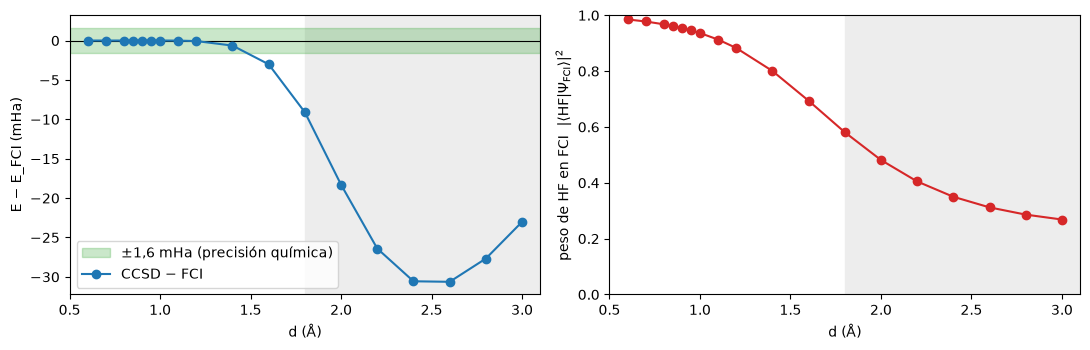

In [12]:
import pandas as pd, matplotlib.pyplot as plt
from h4vqe import config
from h4vqe.hamiltonian import validation_table
val = pd.DataFrame(validation_table(config.DISTANCES))
print(f"{len(val)} distancias | máx |<HF|H|HF> − E_HF| = {val.err_hf.abs().max():.1e} Ha | "
      f"máx |E_0(H, sector 2α2β) − E_FCI| = {val.err_fci.abs().max():.1e} Ha | máx |S²| = {val.s2.abs().max():.1e}")
worst = val.loc[val.ccsd_minus_fci_mHa.idxmin()]
print(f"CCSD convergió en todas: {val.ccsd_converged.all()} | peor CCSD − FCI = {worst.ccsd_minus_fci_mHa:.1f} mHa a {worst.d} Å")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for a in (a1, a2):
    a.axvspan(config.STRETCHED_FROM, val.d.max() + 0.1, color="0.93", zorder=0)
    a.set_xlabel("d (Å)"); a.set_xlim(val.d.min() - 0.1, val.d.max() + 0.1)
a1.axhspan(-1e3 * config.CHEM_ACC, 1e3 * config.CHEM_ACC, color="tab:green", alpha=0.25, label="±1,6 mHa (precisión química)")
a1.axhline(0, color="k", lw=0.8)
a1.plot(val.d, val.ccsd_minus_fci_mHa, "o-", label="CCSD − FCI")
a1.set_ylabel("E − E_FCI (mHa)"); a1.legend(loc="lower left")
a2.plot(val.d, val.w_hf, "o-", color="tab:red")
a2.set_ylabel(r"peso de HF en FCI  $|\langle \mathrm{HF}|\Psi_\mathrm{FCI}\rangle|^2$"); a2.set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 2 · El ansatz  *(Gonzalo)*

Partimos de UCCSD con Trotter: 8 simples + 18 dobles = 26 excitaciones por paso. Cada excitación es exp(−iθG) con G = i(T − T†). Sus términos de Pauli conmutan, así que el circuito es exactamente Π exp(−iθ_k G_k). Eso nos deja optimizar con un simulador numpy (gradiente analítico) y medir **el mismo circuito**.

El problema: UCCSD×2 llega a FCI, pero cuesta ~584 CZ (~1600 en línea). Con 0,1 % de error por CZ eso no sirve.

### ADAPT-VQE: solo las excitaciones que hacen falta

ADAPT (Grimsley et al., 2019) arranca de |HF⟩ y agrega de a una la excitación del pool con gradiente máximo, g_k = ⟨ψ|i[G_k, H]|ψ⟩. Después de cada agregado reoptimiza todos los parámetros. Pool: las 26 excitaciones de UCCSD, que se pueden repetir (`h4vqe/adapt.py`).

**Una lista común para toda la curva.** En cada paso elegimos el operador con mayor gradiente en *cualquiera* de las 18 distancias y reoptimizamos cada una por separado. Así el circuito (y la cantidad de CZ) es el mismo en todos los puntos, y solo cambian los θ.

**Dónde cortar sin usar FCI.** Usamos la varianza de la energía ⟨H²⟩ − ⟨H⟩², que vale 0 solo en un autoestado. Para elegir el corte la calculamos con el estado del simulador: al pasar de 12 a 13 operadores, la varianza máxima sobre la curva cae de 3,2·10⁻³ a 2,6·10⁻⁴ Ha² (y el error máximo, de 3,7 a 0,6 mHa). La misma varianza **medida con shots** por eco de Loschmidt (sección 4) lo confirma: 2,8·10⁻⁴ a 1,8 Å, 7,3·10⁻⁵ a 2,4 Å y 5·10⁻⁶ a 3,0 Å, contra 2,6·10⁻⁴, 6,5·10⁻⁵ y 6,7·10⁻⁶ calculadas.

**Completar los pares de espín.** ADAPT eligió las simples α 0→2 y β 5→7, pero no sus pares β 4→6 y α 1→3, así que el estado rompe un poco el espín (S² ≤ 0,013). Agregamos esas dos simples **al lado de su pareja** (`ADAPT_FERMIONIC`, 15 operadores): el error máximo baja de 0,59 a **0,38 mHa** en toda la curva y S² baja a ≤ 6,5·10⁻³, por 9 CZ más.

**Dos arranques en la optimización.** `optimize_params` prueba siempre el warm start (θ* de la distancia anterior) **y** θ = 0 (|HF⟩), y se queda con la energía más baja (es variacional). Solo con warm start, el optimizador caía en mínimos malos en algunos puntos: 2 mHa a 2,8 Å con la lista de 15, 0,84 mHa a 1,4 Å con la de 13 y 9,8 mHa a 2,0 Å con QEB.

| ansatz | parámetros | CZ (todos con todos) | CZ (línea) | error máx. vs FCI (sin ruido) | S² máx. |
|---|---|---|---|---|---|
| UCCSD ×1 | 26 | 292 | 806 | 4,5 mHa (2,0 Å) | hasta 0,85 |
| UCCSD ×2 | 52 | ~584 | ~1600 | < 0,001 mHa | ≈ 0 |
| ADAPT, 13 ops (`ADAPT_FERMIONIC_13`) | 13 | 185 | 526 (transpiler) / 370 (ruteo fSWAP) | 0,59 mHa (2,0 Å) | 0,013 |
| **ADAPT + pares de espín, 15 ops (`ADAPT_FERMIONIC`)** | **15** | **194** | **530 (transpiler) / 378 (ruteo fSWAP)** | **0,38 mHa** | **6,5·10⁻³** |
| ADAPT-QEB, 15 ops (extra) | 15 | 159 | ~451 (transpiler) | 0,81 mHa | 0,074 |

Las CZ en línea con ruteo fSWAP salen de `routing.line_cz_count(routed_ansatz(m, lista, LINE_ORDER)[0])` (ver abajo). `cz_count(circuito, "line")` usa el transpiler común y da el número más alto.

El pool QEB usa excitaciones de *qubit* (sin cadenas Z de Jordan-Wigner). Conservan N_α y N_β, tocan solo 2 o 4 qubits y cuestan menos CZ.

### Qubits en línea: ruteo propio con fSWAP

Con SWAP comunes, el transpiler multiplica las CZ ~2,8× en línea. Nuestro ruteo (`h4vqe/routing.py`), inspirado en Co-ADAPT (Ramôa et al., 2026) y en las redes fSWAP (Kivlichan et al., 2018), hace tres cosas:

1. Antes de cada excitación junta sus modos en qubits **contiguos** con **fSWAP** (2 CZ cada uno; intercambian dos modos fermiónicos *con* el signo de Jordan-Wigner).
2. **No deshace** la permutación: el orden de los modos se sigue de forma clásica.
3. Aplica cada doble con un circuito pensado para la línea (18 CZ, casi todas entre vecinos) y mide la energía con Ĥ escrito en el **orden final** de modos (`hamiltonian_in_order`).

Los θ son los mismos (las fSWAP solo reetiquetan modos). Verificamos que la energía coincide hasta 1e-15 (`tests/test_routing.py`) y que la medición con shots no tiene sesgo (16 semillas: media de z = 0,14, desvío 0,91). El orden inicial se eligió entre 72 candidatos: [α3 β3 α1 β1 α2 β2 α0 β0]. Resultado: **530 → 378 CZ en línea** (−29 %).

Costo: Ĥ en el orden final se agrupa mucho peor (69 grupos contra 37 con el agrupamiento de la sección 3), así que necesita más shots para la misma σ. Por eso la curva central se mide con el circuito sin rutear y Ĥ original (es el mismo estado); el circuito ruteado se usa para las CZ en línea y para la simulación con ruido.

### Qué no funcionó

- **Umbral de gradiente 1e-4:** ADAPT se frena en mesetas a 1,6, 2,8 y 3,0 Å con 0,6-2 mHa de error, y después el gradiente vuelve a crecer. Con 1e-5 llega a FCI en toda la curva.
- **Agregar las simples de espín al final de la lista:** con el warm start cae en un mínimo malo (2,5 mHa, S² = 0,52). Tienen que ir al lado de su pareja.
- **Optimizar solo con warm start entre distancias:** cae en mínimos locales malos (hasta 9,8 mHa con QEB a 2,0 Å, S² = 0,78). Se arregló probando también θ = 0. QEB es más barato, pero rompe más el espín (S² ≤ 0,074), así que queda como extra.
- **Reordenar los operadores** para necesitar menos fSWAP (314 CZ en línea): el error sube a 5,2 mHa. El orden de los operadores cambia el ansatz.
- **Co-ADAPT** (elegir cada operador por gradiente / costo en línea): necesita 16-19 operadores para precisión química y termina en ~460-470 CZ en línea. En H4 casi todas las dobles hacen falta, así que penalizar por costo solo agrega operadores.
- **Circuitos explícitos de excitación sin ruteo propio** (escalera de CNOT + RY multicontrolada): exactos, pero el transpiler los rutea peor que `PauliEvolutionGate` (705 contra 526 CZ en línea).
- **Probar layouts y semillas del transpiler** para conectividad en línea: el mejor resultado fue ~515 CZ, contra ~526 por defecto.

### Limitaciones y próximos pasos

- S² ≤ 6,5·10⁻³ (no es exactamente 0), porque el pool no está adaptado al espín: los pares de dobles αβ tampoco comparten parámetro.
- Para bajar más las CZ: operadores CEO de 9 CNOT, podar operadores y orbitales localizados u optimizados (rotarlos clásicamente no cuesta CZ).


## 3 · Medir la energía con shots  *(Santino)*

### Cómo medimos

- H tiene 184 términos de Pauli más una constante. Los agrupamos en conjuntos que se miden con **un mismo circuito**. Cada shot de un grupo da una muestra de O_g = Σ c_k P_k. Entonces E_g es la media muestral, σ_g² = var/N_g (con las covarianzas dentro del grupo incluidas), E = c₀ + Σ_g E_g y σ² = Σ_g σ_g², porque los grupos usan shots distintos.
- **Agrupamiento QWC (default)**: términos que conmutan qubit a qubit. Se miden rotando cada qubit (H para X, S†H para Y), **sin CZ extra**. Armamos los grupos por *sorted insertion* (Crawford et al., *Quantum* 5, 385 (2021)): por |c| decreciente, cada término va al primer grupo compatible. Así quedan **37 grupos**, contra los 46 del coloreo de `group_commuting`, y se necesitan **1,6–1,8× menos shots** para la misma σ (tabla de abajo).
- **Agrupamiento GC (opcional, `grouping="gc"`)**: términos que conmutan en general, **9 grupos**. Cada grupo se diagonaliza con un Clifford: tomamos generadores independientes (sobre GF(2)), construimos el estado estabilizador C|0⟩ que fijan y medimos en Z después de C†, porque C†PC = ±Z… para todo P del grupo. Necesita **2–2,8× menos shots que QWC**, pero agrega **4–23 CZ por grupo** con conectividad total (**4–77 con qubits en línea**).
- **Reparto de shots en dos etapas**: primero un piloto con el 10 % del presupuesto y N_g ∝ Σ|c_k|, para estimar σ_g. Después el resto con la asignación de Neyman, N_g ∝ σ_g, que es la que minimiza σ para un N total fijo. Las muestras de las dos etapas se juntan.
- **Semillas**: cada grupo y cada etapa tiene su propia semilla, derivada con `SeedSequence`. Al principio usábamos semillas consecutivas de Aer y vimos errores correlacionados entre grupos, con desvíos de 4σ.
- **Velocidad**: los conteos se arman con `np.bincount` sobre el `BitArray` del `SamplerV2`. Con 8 M de shots, `get_counts()` (un string por shot) se comía la mayor parte del tiempo. Además, los circuitos se transpilan una sola vez.

### Cuántos shots hacen falta

Para un estado |ψ⟩ y fracciones de shots f_g, σ² = Σ_g V_g/(f_g N) con V_g = ⟨O_g²⟩ − ⟨O_g⟩². Por eso **σ = √(K/N)**: la σ baja como 1/√N, y alcanza con calcular K una vez para cada estrategia. Las V_g se calculan con el estado FCI, al que el VQE llega con un error menor que 1 µHa. Esta cuenta **solo sirve para planificar**; la energía reportada sale siempre de los shots (`scripts/shots_study.py`).

Shots necesarios para **σ = 0,5 mHa** (reparto en dos etapas):

| d (Å) | QWC con coloreo (antes) | **QWC con sorted insertion** | GC con coloreo | **GC con sorted insertion** |
|---|---|---|---|---|
| 0,9 | 17,8 M | 11,1 M | 5,3 M | 4,3 M |
| 1,8 | 16,5 M | 9,1 M | 7,2 M | 4,4 M |
| 2,0 | 15,5 M | 8,6 M | 6,8 M | 4,1 M |
| 2,4 | 14,2 M | 8,0 M | 5,9 M | 3,6 M |
| 3,0 | 13,6 M | 8,0 M | 4,9 M | 2,9 M |

**Reparto de shots** (QWC con sorted insertion, 2,0 Å, K en mHa²·M shots):

| reparto | Σ\|c\| | Neyman con varianzas de HF | dos etapas (piloto + Neyman) | Neyman ideal (V_g exactas) |
|---|---|---|---|---|
| K | 3,69 | 24,6 | 2,15 | 2,13 |

Las dos etapas quedan a menos de 1 % del óptimo. Usar las varianzas del estado HF es **11× peor**: HF es un estado de la base computacional, así que da varianza cero a todos los grupos que miden solo Z y les asigna muy pocos shots.

**En 5 qubits** (reducción de Octavio, ansatz compacto): con el coloreo, la reducción costaba ~3× más shots que 8 qubits. Con sorted insertion ese costo desaparece: queda igual que en 8 qubits.

| d (Å) | QWC con coloreo | **QWC con sorted insertion** | GC con sorted insertion |
|---|---|---|---|
| 1,8 | 31 M | 11 M | 4,3 M |
| 2,4 | 28 M | 8,9 M | 3,5 M |
| 3,0 | 25 M | 7,9 M | 3,0 M |

(Shots para σ = 0,5 mHa, sin ruido; `scripts/mitigation_study.py`.)

**Presupuesto elegido**: con QWC, **8 M de shots por punto dan σ = 0,50–0,53 mHa** en la zona estirada (~0,6 mHa cerca del mínimo). Con GC, 4 M dan lo mismo.

### Calibración de σ: ¿la barra de error es honesta?

Repetimos la medición del **mismo circuito** con semillas independientes y miramos z = (E − E_exacta)/σ, donde E_exacta = ⟨ψ|H|ψ⟩ del circuito medido. Si σ está bien, z ~ N(0,1). Hicimos 500 repeticiones por configuración (300 para Σ|c|), a 2,0 y 3,0 Å, con un total de **17,8 mil millones de shots** (`scripts/calib_sigma.py`, ~35 min en 12 núcleos). También calculamos σ por **bootstrap**: re-muestrear los shots de cada grupo y recalcular E.

| configuración | d (Å) | σ media (mHa) | σ predicha √(K/N) | media de z | std de z [IC 95 %] | σ_boot/σ | \|z\|>2 |
|---|---|---|---|---|---|---|---|
| QWC, 8 M, dos etapas | 2,0 | 0,519 | 0,519 | −0,02 ± 0,05 | 1,01 [0,95; 1,07] | 0,997 | 5,0 % |
| QWC, 8 M, dos etapas | 3,0 | 0,500 | 0,500 | +0,04 ± 0,05 | 1,00 [0,94; 1,06] | 0,998 | 4,4 % |
| QWC, 1 M, dos etapas | 2,0 | 1,467 | 1,467 | +0,04 ± 0,05 | 1,03 [0,97; 1,09] | 0,999 | 4,8 % |
| QWC, 1 M, dos etapas | 3,0 | 1,413 | 1,413 | −0,02 ± 0,05 | 1,04 [0,98; 1,11] | 0,999 | 6,2 % |
| QWC, 8 M, Σ\|c\| | 2,0 | 0,679 | 0,679 | −0,16 ± 0,06 | 0,98 [0,91; 1,06] | 0,997 | 5,3 % |
| QWC, 8 M, Σ\|c\| | 3,0 | 0,681 | 0,681 | −0,02 ± 0,06 | 1,03 [0,95; 1,12] | 1,001 | 5,0 % |
| GC, 4 M, dos etapas | 2,0 | 0,507 | 0,507 | +0,01 ± 0,04 | 0,96 [0,91; 1,03] | 0,996 | 3,4 % |
| GC, 4 M, dos etapas | 3,0 | 0,424 | 0,424 | +0,01 ± 0,05 | 1,04 [0,98; 1,11] | 0,994 | 5,8 % |

- **σ está calibrada**: la dispersión de z es compatible con 1 en las 8 configuraciones. Con las 3600 repeticiones juntas: media de z = −0,006 ± 0,017, dispersión = 1,011 [0,988; 1,035], |z|>2 en 5,0 % (normal: 4,6 %), 11 casos con |z|>3 (esperados ~10) y prueba KS contra N(0,1) con p = 0,78. No hay correlación entre repeticiones seguidas (|r| < 0,12). Histogramas: `results/calib_sigma/hist_z.png`. La fórmula √(K/N) predice la σ media hasta el tercer dígito, y de 1 M a 8 M la σ baja en √8 = 2,83 (medido: 2,83).
- **El 1,16 de antes era ruido estadístico**: con 60 repeticiones, aunque σ sea exacta, la dispersión de z cae en [0,82; 1,18] el 95 % de las veces.
- **El bootstrap coincide** con la σ analítica dentro de 0,7 %: la σ no depende de suponer normalidad.
- La media de z = −0,16 ± 0,06 (Σ|c| a 2,0 Å) es un desvío de 2,7σ entre unas 18 pruebas, algo que por azar pasa ~10 % de las veces. No es un sesgo: el mismo circuito medido con dos etapas da −0,02 ± 0,05.

### Qué no funcionó o descartamos

- **Neyman con varianzas de HF**: 11× peor que el piloto (ver arriba).
- **Reusar shots entre grupos** (cada base QWC también estima los Paulis compatibles de otros grupos, promediados por shots): sobre el coloreo gana 1,4–2,3×, pero sobre *sorted insertion* casi no suma. Solo gana 1,5× cerca del mínimo, y en la zona estirada empeora un poco porque el promedio por shots ignora las covarianzas. No lo implementamos.
- **Calibrar con 60 repeticiones**: no alcanza para distinguir 1,16 de 1.

### Limitaciones

- La calibración es **sin ruido**: verifica la estadística de los shots, no el sesgo del ruido. Con ruido, σ sigue midiendo solo la dispersión estadística, y el sesgo se trata en el notebook de extras (mitigación).
- GC baja los shots pero **suma CZ** al circuito medido: con 0,1 % de error por CZ, ~50 CZ más (qubits en línea) son ~5 % más de error. Por eso proponemos QWC para las corridas con ruido: además permite post-seleccionar por N_α y N_β en el grupo que mide solo Z.
- K se planificó con el estado FCI. Si el ansatz cambia, el piloto vuelve a estimar las σ_g en cada punto, así que el reparto se ajusta solo.


In [13]:
import numpy as np, importlib, time
import h4vqe
for mod in ["config","hamiltonian","ansatz","optimize","estimator","adapt","routing","analysis","pipeline"]:
    importlib.reload(importlib.import_module("h4vqe." + mod))
from qiskit.quantum_info import Statevector
from h4vqe import config
from h4vqe.hamiltonian import molecule, qubit_hamiltonian
from h4vqe.ansatz import build_ansatz, cz_count
from h4vqe.pipeline import curve_ansatz_kwargs, line_cz_fswap

m = molecule(2.0); H = qubit_hamiltonian(m)
ans = build_ansatz(m, **curve_ansatz_kwargs())   # config.ANSATZ
e_hf = Statevector(ans.fast.psi0).expectation_value(H).real
print(f"términos de Pauli: {len(H)} | qubits: {H.num_qubits}")
print(f"E_HF (PySCF) = {m['e_hf']:.8f}   <HF|H|HF> = {e_hf:.8f}")
print(f"E_FCI = {m['e_fci']:.8f}   E_CCSD = {m['e_ccsd']:.8f}  (CCSD − FCI = {1e3*(m['e_ccsd']-m['e_fci']):+.2f} mHa)")
x = np.random.default_rng(0).normal(0, .2, ans.num_parameters)
fid = abs(np.vdot(Statevector(ans.circuit.assign_parameters(x)).data, ans.fast.state(x)))**2
print(f"fidelidad circuito Qiskit vs simulador numpy = {fid:.12f}")
print(f"ansatz: {config.ANSATZ} | parámetros: {ans.num_parameters} | CZ: {cz_count(ans.circuit)} (todos con todos), "
      f"{cz_count(ans.circuit, 'line')} (línea, transpiler), {line_cz_fswap(m, ans)} (línea, ruteo fSWAP)")

términos de Pauli: 185 | qubits: 8
E_HF (PySCF) = -1.57561648   <HF|H|HF> = -1.57561648
E_FCI = -1.89778065   E_CCSD = -1.91608610  (CCSD − FCI = -18.31 mHa)
fidelidad circuito Qiskit vs simulador numpy = 1.000000000000
ansatz: adapt | parámetros: 15 | CZ: 194 (todos con todos), 543 (línea, transpiler), 378 (línea, ruteo fSWAP)


## 4 · Resultados: curva, R_e y D_e  *(Joaquín)*

Para cada distancia: hamiltoniano → ansatz → θ* (sin ruido, con warm start desde el punto anterior) → **energía medida** con shots. La tabla tiene, por punto, la energía, su σ, los shots y las CZ: todos con todos (`cz_all`), en línea con el transpiler de Qiskit (`cz_line`) y en línea con nuestro ruteo fSWAP (`cz_line_fswap`, sección 2). El circuito ruteado prepara el mismo estado con los modos reordenados; medimos el circuito sin rutear con Ĥ original porque Ĥ reordenado necesita ~1,9× más grupos QWC.

**Cómo sacamos R_e y D_e.** El mínimo sale de ajustar las energías medidas cerca de 0,9 Å. La σ se obtiene por Monte Carlo: re-muestreamos cada energía con su σ y re-ajustamos, incluida la elección de los puntos.

**Cómo elegimos el ajuste.** Probamos 7 modelos: cuadrático en 3 y 5 puntos, cúbico en 6 y 7, cuártico en 7 y 8, y spline cúbico entre 0,6 y 1,6 Å. Para elegir **sin mirar el VQE**, aplicamos cada modelo a las energías FCI de la *misma grilla* y lo comparamos con el mínimo FCI verdadero, que sacamos minimizando PySCF en d (R_e = 0,8886 Å). Esa diferencia es el sesgo del *método de ajuste*:

| modelo | sesgo en R_e | sesgo en E_min | σ(R_e) con nuestras barras |
|---|---|---|---|
| cuadrático, 5 puntos (el que usábamos) | **+7,8 mÅ** | +126 µHa | 2,2 mÅ |
| cúbico, 7 puntos | +0,4 mÅ | **−575 µHa** | 2,5 mÅ |
| **cuártico, 7 puntos (0,7–1,1 Å)** | **−0,9 mÅ** | **−16 µHa** | 2,3 mÅ |
| spline 0,6–1,6 Å | −0,5 mÅ | −5 µHa | 7,6 mÅ |

El cuadrático tiene un sesgo de 3σ: la curva es asimétrica (sube más rápido hacia la izquierda) y una parábola corre el mínimo hacia afuera. El spline no tiene sesgo, pero pasa por cada punto con su ruido y queda 3 veces más ruidoso. La elección tampoco depende de FCI: el cuártico en 7 puntos recupera el mínimo de una curva de Morse conocida en esta misma grilla, con error < 2 mÅ en R_e y < 0,1 mHa en E_min (`tests/test_analysis.py`). La comparación con FCI solo elige un método numérico; no corrige ningún resultado.

**Elegimos el cuártico en 7 puntos**: es el único con sesgo chico en R_e *y* en E_min a la vez, y su σ es de las más chicas. Las diferencias entre modelos de bajo sesgo (≈ 2 mÅ en R_e, ≲ 0,1 mHa en D_e) quedan dentro de la σ estadística.

**Resultado** (corrida completa, ADAPT 15 operadores, 194 CZ, 8M shots por punto):

| | VQE (medido) | FCI | diferencia |
|---|---|---|---|
| R_e | 0,8873 ± 0,0018 Å | 0,8886 Å | −1,2 mÅ (−0,7σ) |
| D_e = E(3,0 Å) − E(R_e) | 313,00 ± 0,66 mHa | 313,21 mHa | −0,21 mHa (−0,3σ) |

Las dos diferencias están dentro de 1σ. El sesgo del ajuste (−0,9 mÅ) y el error de ADAPT sin ruido (≤ 0,38 mHa) quedan debajo de la σ de shots.

En la zona estirada (d ≥ 1,8 Å) le ganamos a CCSD en 7/7 puntos contando la σ, y tenemos precisión química en 7/7 (error máximo: 0,56 mHa, a 2,4 Å). En toda la curva el error máximo es 1,15 mHa (0,7 Å). La σ por punto es 0,50–0,60 mHa. La σ de D_e está dominada por las dos energías que entran en la resta. Para bajarla hacen falta más shots en el mínimo y a 3,0 Å, no un ajuste mejor.

> Las celdas de abajo recalculan todo esto en cada ejecución. Si cambian el ansatz o los shots, los números de esta sección se actualizan ahí.


In [14]:
from h4vqe.pipeline import run_curve
QUICK = False   # True: 4 distancias y menos shots, para probar rápido
dists = [0.7, 0.9, 1.8, 3.0] if QUICK else config.DISTANCES
shots = 400_000 if QUICK else config.SHOTS_PER_POINT
t0 = time.time()
rows, ctxs = run_curve(dists, shots=shots)
print(f"total: {time.time()-t0:.0f} s")

d=0.60 Å  E=-1.960988 ± 0.59 mHa  |E-FCI|=0.79 mHa  |CCSD-FCI|=0.00 mHa  CZ=194  (3s)


d=0.70 Å  E=-2.105850 ± 0.58 mHa  |E-FCI|=1.15 mHa  |CCSD-FCI|=0.00 mHa  CZ=194  (3s)


d=0.80 Å  E=-2.167708 ± 0.58 mHa  |E-FCI|=0.15 mHa  |CCSD-FCI|=0.00 mHa  CZ=194  (3s)


d=0.85 Å  E=-2.177530 ± 0.55 mHa  |E-FCI|=0.78 mHa  |CCSD-FCI|=0.01 mHa  CZ=194  (3s)


d=0.90 Å  E=-2.179990 ± 0.59 mHa  |E-FCI|=0.33 mHa  |CCSD-FCI|=0.01 mHa  CZ=194  (3s)


d=0.95 Å  E=-2.176401 ± 0.60 mHa  |E-FCI|=0.62 mHa  |CCSD-FCI|=0.01 mHa  CZ=194  (3s)


... (8 outputs left out)

d=2.40 Å  E=-1.874095 ± 0.50 mHa  |E-FCI|=0.56 mHa  |CCSD-FCI|=30.56 mHa  CZ=194  (4s)


d=2.60 Å  E=-1.870658 ± 0.50 mHa  |E-FCI|=0.19 mHa  |CCSD-FCI|=30.63 mHa  CZ=194  (5s)


d=2.80 Å  E=-1.868846 ± 0.51 mHa  |E-FCI|=0.50 mHa  |CCSD-FCI|=27.67 mHa  CZ=194  (4s)


d=3.00 Å  E=-1.867339 ± 0.51 mHa  |E-FCI|=0.05 mHa  |CCSD-FCI|=23.01 mHa  CZ=194  (4s)
total: 69 s


In [15]:
import pandas as pd
from h4vqe.analysis import results_table
df = results_table(rows)
cols = ["d","E_vqe","sigma_mHa","shots","cz_all","cz_line","cz_line_fswap","E_fci","E_ccsd","err_vqe_mHa","err_ccsd_mHa","beats_ccsd","chem_acc"]
pd.set_option("display.float_format", lambda v: f"{v:.6f}")
df[cols]

,d,E_vqe,sigma_mHa,shots,cz_all,cz_line,cz_line_fswap,E_fci,E_ccsd,err_vqe_mHa,err_ccsd_mHa,beats_ccsd,chem_acc
0,0.600000,-1.960988,0.588574,7999980,194,543,378,-1.960194,-1.960189,0.794317,0.004758,NaN,True
1,0.700000,-2.105850,0.581550,7999978,194,543,378,-2.106997,-2.106993,1.146774,0.004243,NaN,True
2,0.800000,-2.167708,0.580017,7999978,194,543,378,-2.167561,-2.167556,0.147764,0.004957,NaN,True
3,0.850000,-2.177530,0.548940,7999982,194,543,378,-2.178314,-2.178308,0.783825,0.005956,NaN,True
4,0.900000,-2.179990,0.589954,7999983,194,543,378,-2.180317,-2.180309,0.327018,0.007204,NaN,True
5,0.950000,-2.176401,0.595121,7999980,194,543,378,-2.175780,-2.175772,0.620517,0.008205,NaN,True
6,1.000000,-2.165495,0.594685,7999979,194,543,378,-2.166387,-2.166380,0.892498,0.007928,NaN,True
7,1.100000,-2.138347,0.592905,7999981,194,543,378,-2.137971,-2.137975,0.376736,0.004921,NaN,True
8,1.200000,-2.102567,0.593412,7999981,194,543,378,-2.102608,-2.102671,0.041191,0.062659,NaN,True
9,1.400000,-2.027987,0.579450,7999983,194,543,378,-2.029070,-2.029707,1.083653,0.636448,NaN,True


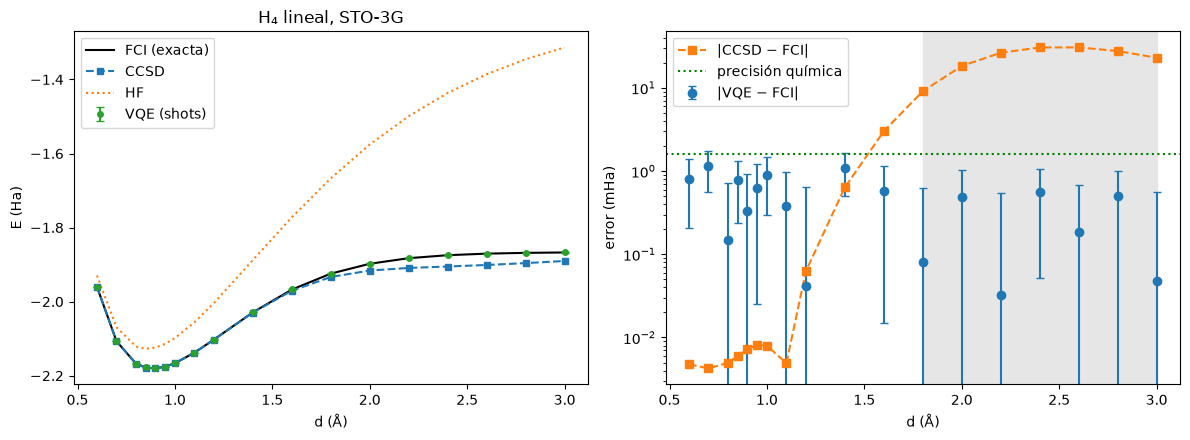

In [16]:
from h4vqe.analysis import plot_curve
fig = plot_curve(df, "curva_h4.png")

In [17]:
from h4vqe.analysis import fit_minimum, dissociation_energy, fci_minimum, compare_fits, DEFAULT_FIT
# Referencia: mínimo FCI verdadero (minimizando PySCF en d), NO un ajuste sobre la grilla.
ref = fci_minimum()
far = df[df.d == df.d.max()].iloc[0]
De_fci = far.E_fci - ref["E_min"]
# Comparación de modelos. "sesgo" = modelo aplicado a FCI en la misma grilla − mínimo verdadero:
# mide el error del método de ajuste, sin mirar el VQE. Con eso elegimos el modelo.
cmp = compare_fits(df, ref)
display(cmp.round(3))
fit = fit_minimum(df.d, df.E_vqe, df.sigma, DEFAULT_FIT)
de = dissociation_energy(far.E_vqe, far.sigma, fit)
print(f"modelo: {fit['model']} sobre d = {fit['fit_points']}")
print(f"R_e (VQE) = {fit['R_e']:.4f} ± {fit['R_e_sigma']:.4f} Å   | R_e (FCI) = {ref['R_e']:.4f} Å   "
      f"→ diferencia {1e3*(fit['R_e']-ref['R_e']):+.1f} mÅ = {(fit['R_e']-ref['R_e'])/fit['R_e_sigma']:+.1f} σ")
print(f"D_e (VQE) = {1e3*de['D_e']:.2f} ± {1e3*de['D_e_sigma']:.2f} mHa | D_e (FCI) = {1e3*De_fci:.2f} mHa  "
      f"→ diferencia {1e3*(de['D_e']-De_fci):+.2f} mHa = {(de['D_e']-De_fci)/de['D_e_sigma']:+.1f} σ")
s = df[df.d >= config.STRETCHED_FROM]
print(f"zona estirada: le gana a CCSD en {int(s.beats_ccsd.sum())}/{len(s)} puntos; precisión química en {int(s.chem_acc.sum())}/{len(s)}")

,modelo,n_puntos,R_e (Å),σ R_e (mÅ),D_e (mHa),σ D_e (mHa),sesgo R_e (mÅ),sesgo E_min (µHa),R_e − R_e(FCI) (mÅ),D_e − D_e(FCI) (mHa)
0,cuadrático 3,3,0.895000,3.848000,312.677000,0.760000,1.755000,66.362000,6.774000,-0.538000
1,cuadrático 5,5,0.896000,1.369000,312.902000,0.650000,7.793000,125.928000,7.333000,-0.313000
2,cúbico 6,6,0.887000,1.972000,313.281000,0.632000,-2.067000,-169.819000,-1.415000,0.067000
3,cúbico 7,7,0.888000,1.499000,313.513000,0.590000,0.384000,-575.260000,-0.065000,0.299000
4,cuártico 7,7,0.887000,1.739000,313.002000,0.655000,-0.873000,-15.697000,-1.232000,-0.212000
5,cuártico 8,8,0.887000,1.485000,312.852000,0.610000,-1.918000,217.493000,-1.880000,-0.362000
6,"spline 0,6–1,6 Å",11,0.897000,8.142000,312.659000,0.747000,-0.510000,-4.759000,8.508000,-0.555000


modelo: cuártico 7 sobre d = [0.7, 0.8, 0.85, 0.9, 0.95, 1.0, 1.1]
R_e (VQE) = 0.8873 ± 0.0018 Å   | R_e (FCI) = 0.8886 Å   → diferencia -1.2 mÅ = -0.7 σ
D_e (VQE) = 313.00 ± 0.66 mHa | D_e (FCI) = 313.21 mHa  → diferencia -0.21 mHa = -0.3 σ
zona estirada: le gana a CCSD en 7/7 puntos; precisión química en 7/7


## 5 · ¿Por qué confiar en la zona estirada?  *(Joaquín)*

La consigna pide argumentar la confiabilidad **antes** de comparar con FCI. Entonces todo lo de esta sección se **mide con shots** (SamplerV2 de Aer) y no usa FCI. FCI aparece recién en la última tabla, como comprobación.

En tres puntos estirados (1,8, 2,4 y 3,0 Å) comparamos cuatro estados preparados con circuitos: **HF** (θ = 0), **ADAPT con 12 operadores** (el paso anterior al corte; 169 CZ), el **ansatz de la curva** (ADAPT, 15 operadores; 194 CZ) y **UCCSD ×2** (52 parámetros; 582 CZ), mucho más profundo.

**1. Principio variacional.** Para cualquier estado, E(θ) ≥ E₀, salvo ruido estadístico (±σ). Por eso, entre estados variacionales, el que da la energía más baja es el mejor. CCSD no es variacional: en la zona estirada queda *por debajo* de la exacta, y ahí "más bajo" no quiere decir "mejor".

**2. Varianza de la energía medida por grupos.** En un autoestado, Var(H) = ⟨H²⟩ − ⟨H⟩² = 0. La medimos como ⟨(H−c)²⟩ − (⟨H⟩−c)², con ⟨(H−c)²⟩ medido con el mismo estimador que la energía: (H−c)² tiene 1775 cadenas de Pauli, que se miden en 225 grupos QWC. Tomamos c = término constante de H porque reduce σ a la mitad respecto de c = E.
*Resultado y limitación:* con 2M de shots, σ ≈ 1,5–2·10⁻³ Ha². HF da 0,12, 0,15 y 0,18 Ha² (1,8, 2,4 y 3,0 Å). Los tres ansätze dan entre 0 y 2·10⁻³ Ha², compatibles con 0 y al menos 50 veces menos que HF. Como es una resta de números grandes, no separa los ansätze entre sí, y por ruido puede dar negativa: en la tabla se muestra recortada en 0, con su σ. Esta medición solo separa HF del resto; la que resuelve es el eco.

**3. Varianza por eco de Loschmidt.** Es la forma fina de medir lo mismo. El circuito prepara ψ, lo evoluciona con e^{−iHt} y lo des-prepara con U(θ)†:

  P(no volver a |0…0⟩) = 1 − |⟨ψ|e^{−iHt}|ψ⟩|² = Var(H)·t² + O(t⁴).

En vez de restar dos números grandes, cuenta **eventos raros**: si ψ es un autoestado, no vuelve ningún shot "mal". Con N shots y 0 eventos, la cota del 95 % es Var ≲ 3/(N t²). Usamos t = 1 Ha⁻¹ y Suzuki-Trotter de 2º orden con 4 pasos. El error de Trotter lo verificamos sin FCI, comparando 2 contra 4 pasos: escala como 1/n⁴ y con 4 pasos es 9·10⁻⁸, debajo de la resolución de 10⁶ shots. A orden dominante, el eco *subestima* Var (Mandelstam-Tamm); a t = 1 la diferencia es ~8 % para UCCSD ×1.
**Resultado:** con 10⁶ shots, el ansatz de la curva da Var = 1,9·10⁻⁴ (1,8 Å), 9·10⁻⁵ (2,4 Å) y 5·10⁻⁶ Ha² (3,0 Å), igual a la calculada con el estado. ADAPT con 12 operadores da entre 7 y 18 veces más (2,9·10⁻³, 6,2·10⁻⁴ y 8,9·10⁻⁵ Ha²), y UCCSD ×2 no tiene ningún evento (Var ≤ 3·10⁻⁶ Ha²). HF da 0,11–0,16 Ha².
*Costo:* el circuito de eco tiene U(θ), la evolución con Trotter y U(θ)†: entre 4100 y 5700 CZ según el estado (columna `echo_cz`). **Es un diagnóstico de simulador sin ruido, no una propuesta para hardware**: con 0,1 % de error por CZ, el ruido taparía la señal. En hardware, el diagnóstico equivalente es la varianza por grupos, con más shots.
*Qué implica:* por la cota de Weinstein, hay un autovalor exacto de Ĥ a menos de √Var de la energía medida: ≤ 15 mHa a 1,8 Å y ≤ 2,3 mHa a 3,0 Å. Esa cota es floja; la que importa es la de segundo orden: si hay un gap Δ al primer excitado del mismo sector, el error es E − E₀ ≈ Var/Δ. Con Var ~10⁻⁴ Ha², ese error queda debajo de la σ de shots (0,5 mHa) si Δ ≳ 0,2 Ha. No medimos Δ; el punto 5 lo chequea de otra forma: un ansatz mucho más profundo no baja la energía. Que ese autovalor sea el fundamental lo sostienen los puntos 1, 4 y 5: es el estado variacional más bajo que encontramos, tiene las simetrías correctas y no baja más al agregar profundidad.

**4. Simetrías medidas.** H₄ tiene un fundamental singlete con N_α = N_β = 2. Medimos ⟨N_α⟩, ⟨N_β⟩ y ⟨S²⟩ con shots:
- **N_α y N_β dan exactamente 2 en todos los shots**: el ansatz de excitaciones conserva el número de partículas.
- **S² es la prueba que discrimina estados de espín mezclado.** Al estirar, el singlete y el triplete se acercan. UCCSD ×1 (un solo paso de Trotter, que no está adaptado al espín) converge a una mezcla, con ⟨S²⟩ medido de 0,64 a 2,4 Å y 0,85 a 3,0 Å, y a 3,0 Å su energía medida no se distingue de la buena: la energía sola no lo delata, la S² medida sí. Por eso la lista de ADAPT completa los pares de espín de las excitaciones simples (sección 2). El ansatz de la curva da |S²| ≤ 0,011 ± 0,012, compatible con 0, igual que HF y UCCSD ×2. Un triplete puro da 2.

**5. Convergencia con la profundidad.** Dos comparaciones, con energías medidas:
- **Hacia abajo** (ADAPT 12 → 15 operadores): la energía baja 2,4 ± 0,8 mHa a 1,8 Å y 1,4 ± 0,7 mHa a 2,4 Å; a 3,0 Å no cambia dentro del ruido (−0,6 ± 0,7 mHa). La varianza por eco cae entre 7 y 18 veces en los tres puntos. Los operadores 13 a 15 hacen falta.
- **Hacia arriba** (15 operadores → UCCSD ×2, con 3 veces más CZ): la energía medida cambia 0,6 ± 0,8, −0,1 ± 0,7 y 1,1 ± 0,7 mHa (1,8, 2,4 y 3,0 Å), todo dentro de 1,6σ. Profundizar mucho más no mejora nada que los shots puedan resolver.

La varianza de UCCSD ×2 sí es menor (≤ 3·10⁻⁶ contra ~10⁻⁴ Ha²): ADAPT no es un autoestado exacto. Pero la energía medida no lo distingue de UCCSD ×2, y por eso elegimos el circuito con menos CZ.

**6. Barras de error calibradas.** Ver la calibración de σ en la sección de medición (Santino).

> La tabla siguiente reúne todo lo medido. La última celda compara recién ahí con FCI.


In [18]:
from h4vqe.pipeline import run_reliability
# Tres puntos de la zona estirada; en cada uno, HF, un ansatz menos profundo (ADAPT 12 ops),
# el de la curva (ADAPT 15 ops) y uno más profundo (UCCSD ×2). Ver pipeline.depth_references.
rel_d = [1.8, 3.0] if QUICK else [1.8, 2.4, 3.0]
t0 = time.time()
rel = pd.DataFrame(run_reliability(ctxs, rel_d, shots=shots,
                                   var_shots=500_000 if QUICK else 2_000_000,
                                   echo_shots=200_000 if QUICK else 1_000_000,
                                   sym_shots=100_000 if QUICK else 200_000))
print(f"total: {time.time()-t0:.0f} s")
# Var(grupos) puede salir negativa por ruido (σ ≈ 2e-3 Ha²): se muestra recortada en 0, con su σ.
# Solo separa HF del resto; la que resuelve es la del eco.
rel["var_grupos (≥0)"] = rel["var"].clip(lower=0)
# echo_cz: CZ del circuito de eco (U, e^{−iHt}, U†). Es un diagnóstico de simulador, no de hardware.
show = rel[["d","rol","estado","cz","E","sigma","var_grupos (≥0)","var_sigma","var_echo","var_echo_up95","echo_events",
            "echo_cz","N_alpha","N_alpha_sigma","N_beta","N_beta_sigma","S2","S2_sigma","var_exacta"]]
with pd.option_context("display.float_format", lambda v: f"{v:.3g}"):
    display(show)

d=1.80 HF                   E=-1.667211±0.50 mHa  Var(grupos)=1.2e-01±2e-03  Var(eco)=1.1e-01 (≤1e-01)  N_α=2.000 N_β=2.000 S²=0.002  (13s)


d=1.80 ADAPT 12 ops (12 θ)  E=-1.921157±0.54 mHa  Var(grupos)=2.6e-03±2e-03  Var(eco)=2.9e-03 (≤3e-03)  N_α=2.000 N_β=2.000 S²=0.001  (9s)


d=1.80 curva (15 θ)         E=-1.923536±0.54 mHa  Var(grupos)=-7.5e-04±2e-03  Var(eco)=1.9e-04 (≤2e-04)  N_α=2.000 N_β=2.000 S²=-0.001  (10s)


d=1.80 UCCSD ×2 (52 θ)      E=-1.924183±0.53 mHa  Var(grupos)=1.8e-03±2e-03  Var(eco)=0.0e+00 (≤3e-06)  N_α=2.000 N_β=2.000 S²=0.006  (16s)


d=2.40 HF                   E=-1.435514±0.53 mHa  Var(grupos)=1.5e-01±2e-03  Var(eco)=1.4e-01 (≤1e-01)  N_α=2.000 N_β=2.000 S²=0.011  (14s)


d=2.40 ADAPT 12 ops (12 θ)  E=-1.873091±0.51 mHa  Var(grupos)=1.1e-03±2e-03  Var(eco)=6.2e-04 (≤7e-04)  N_α=2.000 N_β=2.000 S²=0.008  (10s)


... (3 outputs left out)

d=3.00 ADAPT 12 ops (12 θ)  E=-1.866925±0.51 mHa  Var(grupos)=-6.2e-04±1e-03  Var(eco)=8.9e-05 (≤1e-04)  N_α=2.000 N_β=2.000 S²=0.002  (10s)


d=3.00 curva (15 θ)         E=-1.866331±0.51 mHa  Var(grupos)=1.8e-03±1e-03  Var(eco)=5.0e-06 (≤1e-05)  N_α=2.000 N_β=2.000 S²=0.011  (11s)


d=3.00 UCCSD ×2 (52 θ)      E=-1.867443±0.50 mHa  Var(grupos)=8.3e-05±1e-03  Var(eco)=0.0e+00 (≤3e-06)  N_α=2.000 N_β=2.000 S²=-0.013  (17s)
total: 159 s


,d,rol,estado,cz,E,sigma,var_grupos (≥0),var_sigma,var_echo,var_echo_up95,echo_events,echo_cz,N_alpha,N_alpha_sigma,N_beta,N_beta_sigma,S2,S2_sigma,var_exacta
0,1.8,HF,HF,0,-1.67,0.000505,0.118,0.00192,0.108,0.109,108066,4130,2,0,2,0,0.00246,0.0109,0.115
1,1.8,menos profundo,ADAPT 12 ops (12 θ),169,-1.92,0.000542,0.00259,0.002,0.00291,0.003,2910,4560,2,0,2,0,0.00101,0.0116,0.00315
2,1.8,curva,curva (15 θ),194,-1.92,0.000537,0,0.00199,0.000189,0.000213,189,4622,2,0,2,0,-0.00122,0.0118,0.000187
3,1.8,más profundo,UCCSD ×2 (52 θ),582,-1.92,0.000534,0.00179,0.00198,0,3e-06,0,5018,2,0,2,0,0.00591,0.0117,5.18e-10
4,2.4,HF,HF,0,-1.44,0.000527,0.15,0.00153,0.139,0.139,138768,4130,2,0,2,0,0.0106,0.0109,0.148
5,2.4,menos profundo,ADAPT 12 ops (12 θ),169,-1.87,0.00051,0.00109,0.00159,0.000624,0.000667,624,4560,2,0,2,0,0.0083,0.0118,0.000722
6,2.4,curva,curva (15 θ),194,-1.87,0.000504,0,0.00158,9.2e-05,0.000109,92,4622,2,0,2,0,0.00994,0.0117,8.74e-05
7,2.4,más profundo,UCCSD ×2 (52 θ),582,-1.87,0.0005,0,0.00157,0,3e-06,0,5018,2,0,2,0,0.0142,0.0114,3.17e-10
8,3,HF,HF,0,-1.31,0.000546,0.177,0.00141,0.163,0.164,163464,4130,2,0,2,0,-0.00403,0.0109,0.176
9,3,menos profundo,ADAPT 12 ops (12 θ),169,-1.87,0.000506,0,0.00149,8.9e-05,0.000106,89,4560,2,0,2,0,0.00152,0.0117,8.3e-05


In [19]:
# Convergencia con la profundidad (sin FCI). Si el ansatz de la curva convergió:
#   - el menos profundo da una energía MEDIDA más alta y una varianza (eco) mayor;
#   - el más profundo (muchas más CZ) no baja la energía medida más allá de σ.
E = rel.pivot(index="d", columns="rol", values="E")
S = rel.pivot(index="d", columns="rol", values="sigma")
by = lambda rol, col: rel[rel.rol == rol].set_index("d")[col]
conv = pd.DataFrame({
    "E(menos) − E(curva) [mHa]": 1e3*(E["menos profundo"] - E["curva"]),
    "σ₁ [mHa]": 1e3*np.hypot(S["menos profundo"], S["curva"]),
})
if "más profundo" in E:
    conv["E(curva) − E(más) [mHa]"] = 1e3*(E["curva"] - E["más profundo"])
    conv["σ₂ [mHa]"] = 1e3*np.hypot(S["curva"], S["más profundo"])
conv["Var eco menos [Ha²]"] = by("menos profundo", "var_echo")
conv["Var eco curva ≤ [Ha²] (95 %)"] = by("curva", "var_echo_up95")
with pd.option_context("display.float_format", lambda v: f"{v:.3g}"):
    display(conv)
# Recién ahora, como comprobación: el error real contra FCI.
chk = df.set_index("d").loc[rel_d, ["err_vqe_mHa", "sigma_mHa", "err_ccsd_mHa"]]
chk

,E(menos) − E(curva) [mHa],σ₁ [mHa],E(curva) − E(más) [mHa],σ₂ [mHa],Var eco menos [Ha²],Var eco curva ≤ [Ha²] (95 %)
d,,,,,,
1.8,2.38,0.763,0.647,0.757,0.00291,0.000213
2.4,1.35,0.717,-0.148,0.71,0.000624,0.000109
3,-0.594,0.717,1.11,0.713,8.9e-05,1.05e-05


,err_vqe_mHa,sigma_mHa,err_ccsd_mHa
d,,,
1.800000,0.080282,0.537071,9.107638
2.400000,0.556582,0.504567,30.559966
3.000000,0.047958,0.507951,23.013003


## 6 · Qué decidimos, qué no funcionó y limitaciones

| decisión | por qué | alternativa descartada |
|---|---|---|
| ADAPT-VQE fermiónico, lista común de 15 operadores | 194 CZ (378 en línea con fSWAP) y error sin ruido ≤ 0,38 mHa; el mismo circuito en toda la curva | UCCSD ×2: exacto, pero 582 CZ (1648 en línea). Compacto de 5 qubits (16 CZ): no conserva N ni S² por construcción y no escala; queda para FakeFez |
| medir el circuito sin rutear con Ĥ original | es el mismo estado que el ruteado; Ĥ reordenado necesita ~1,9× más grupos QWC | medir el circuito ruteado (las 378 CZ en línea se reportan aparte) |
| optimizar sin ruido | permitido; mucho más rápido | SPSA con shots: lento y ruidoso |
| SamplerV2 + σ propia | barras honestas, permite Neyman | EstimatorV2 con `precision`: σ fija |
| R_e con cuártico en 7 puntos (0,7–1,1 Å) | sesgo < 1 mÅ al aplicarlo a FCI en la misma grilla | cuadrático en 5 puntos: sesgo de +8 mÅ, mayor que σ |
| referencia R_e(FCI) minimizando PySCF | compara el VQE contra la verdad, no contra otro ajuste | ajustar FCI con el mismo modelo (esconde el sesgo del ajuste) |
| varianza por eco de Loschmidt | cuenta eventos raros: resuelve Var ~ 10⁻⁶ Ha² con 1M shots | solo ⟨H²⟩ por grupos QWC: σ ≈ 3·10⁻³ Ha² (no separa ×1 de ×2) |

**Qué no funcionó:**
- Semillas consecutivas en el Sampler ⇒ σ subestimada (corregido).
- La misma semilla en las 18 distancias ⇒ ruido de shots correlacionado entre puntos vecinos (detectado por Gonzalo: ~3σ seguidos en 0,7–0,9 Å con 200 k shots). Eso sesga el ajuste de R_e y hace que su σ de Monte Carlo, que supone errores independientes, quede chica. Ahora cada punto y cada diagnóstico usa su propia semilla, separadas por un paso de 1000 para que no choquen con las semillas derivadas del estimador (seed+1 de la etapa de Neyman).
- Medir la varianza como ⟨H²⟩ − ⟨H⟩² con grupos QWC: (H−c)² tiene 1775 Paulis en 225 grupos y cada grupo fluctúa mucho aunque el total sea ≈ 0, así que la σ queda en ~10⁻³ Ha² aunque se usen millones de shots. Restar la constante de H (c) reduce σ a la mitad, pero no alcanza. Lo dejamos como medición directa y sumamos el eco.
- Eco con 2 pasos de Trotter: el error de Trotter (1,3·10⁻⁶) se confundía con la señal. Con 4 pasos baja a 9·10⁻⁸.

**Limitaciones**
- **Compuertas:** el ansatz de la curva tiene 194 CZ con conectividad total y 378 con qubits en línea (columnas `cz_all` y `cz_line_fswap`). Sin ruido no importa, pero con 0,1 % de error por CZ la probabilidad de que no falle ninguna es 0,999^194 ≈ 82 % (todos con todos) y 0,999^378 ≈ 69 % (en línea). En hardware haría falta mitigar; eso está en el notebook de extras, con un ansatz de 16 CZ.
- **Optimización sin ruido:** los parámetros se buscan con el simulador exacto, como permite la consigna. La curva mide qué tan expresivo es el ansatz más el ruido de los shots, no la dificultad de optimizar con mediciones.
- **σ es solo estadística:** cubre la dispersión de los shots (calibrada en la sección 3), no sesgos de ruido de compuertas o de lectura, que en esta simulación no hay.
- **Diagnósticos de la sección 5:** se miden con shots, pero el eco de Loschmidt usa ~4600 CZ. Es un diagnóstico de simulador; en hardware el equivalente es la varianza por grupos, con más shots.
- **Costo en shots:** 8 M por punto (144 M en las 18 distancias) para σ ≈ 0,5–0,6 mHa.
